# EDA 4 — H2: covariables del hogar y la brecha entre el aviso y la denuncia

**Qué decide este notebook.** Es el soporte de **H2**, la última hipótesis abierta del caso (D4) y la que se presenta el 31 de octubre:

> **H2.** En violencia familiar, la brecha llamadas/carpeta por AGEB **disminuye** con la escolaridad (`GRAPROES`) y la derechohabiencia (`PDER_SS`), y **aumenta** con el hacinamiento (`PRO_OCUP_C`).

Se construye en dos pasos, en dos secciones separadas y en este orden:

| Sección | Experimento | Qué hace | Salida |
|---|---|---|---|
| 1–5 | **2.2** | Une RESAGEBURB 2020 con el universo de `11_`, describe las tres covariables, cuenta los `*` de confidencialidad y los ceros, aplica las exclusiones de S5 y mide **cuánta carpeta se va con ellas**. Reporta **VIF y la matriz de correlación entre covariables** | `resultados/12_ageb_covariables_resageburb.csv` |
| 6+ | **3.1** | La regresión de H2 con errores espaciales, las cinco sensibilidades y el placebo espacial | `resultados/16_h2_regresion_brecha_covariables.csv` |

**En esta corrida solo está el 2.2.** La separación es deliberada y es la misma disciplina del 5, el 8 y el 11 de octubre: **primero se fija la regla, después se mira el resultado**.

> ⚠️ **En las secciones 1–5 no se calcula ninguna asociación entre las covariables y la brecha.** Ni una correlación, ni un gráfico de dispersión, ni una tabla cruzada por clase de brecha. La columna de la brecha se arrastra en el CSV porque el 3.1 la necesita, pero aquí no se usa para nada más que contar unidades. Si se mirara esa asociación ahora, la regla del §3 de `PLAN_31_OCT.md` dejaría de ser una predicción.

**La regla de decisión quedó fijada el 16 de octubre de 2026** en `PLAN_31_OCT.md` §3, antes de ejecutar esta celda. En resumen, y por si el plan no está a la mano:
- **Escala y modelo:** log de la brecha (= logit empírico de llamadas/(llamadas+carpetas), corrección de 0.5), covariables estandarizadas, efecto fijo de ventana, MCP con pesos 1/(σ̂²_AGEB + v) donde v = 1/(llamadas+0.5) + 1/(carpetas+0.5) es la varianza binomial **conocida**.
- **Errores estándar:** espacialmente robustos tipo Conley, kernel de Bartlett, **ancho de banda 2 km**, elegido porque el correlograma del 2.5 sitúa la dependencia en 1–2 km y la encuentra en cero a partir de ahí. No por conveniencia.
- **Veredicto por covariable:** se **acepta** si el signo es el predicho, el IC 95% espacial excluye el cero y el signo se mantiene en las cinco sensibilidades; se **rechaza** si el IC excluye el cero con el signo contrario; **no concluye** si incluye el cero o el signo cambia entre variantes. Los tres desenlaces están previstos y los tres se reportan.
- **Declarado de antemano:** se espera un R² pequeño. Con mosaico de barrio a 1–2 km (I de Moran corregido 0.245), tres covariables de AGEB no van a explicar la brecha. **El R² no es el criterio**; el criterio es el signo con un intervalo honesto.

**Supuestos que aplican aquí** (formato del criterio transversal — *por qué es válido en este contexto*, no *qué se hizo*):
- **S5 (falacia ecológica y denominador).** Uso las covariables de RESAGEBURB como descriptores de los hogares del AGEB y las viviendas particulares habitadas como denominador, asumiendo que el AGEB del hecho es el del domicilio —en violencia familiar el hecho ocurre en la vivienda, y en las dos fuentes la coordenada es la del lugar— y que los hogares afectados se parecen al promedio de su AGEB. Si la violencia se concentrara en subgrupos dentro del AGEB, **H2 se lee como asociación territorial y no individual**; la inferencia individual solo la da la ENDIREH, que no baja a AGEB.
- **S6 (la brecha no es el subregistro).** La brecha mezcla la propensión a *llamar* con la propensión a *denunciar*. Si las covariables movieran la primera, H2 estaría midiendo dos mecanismos a la vez. Control pendiente y declarado como trabajo futuro: las llamadas de otros motivos en el mismo AGEB como proxy de la propensión a llamar.
- **Nada de esto es causal.** Tres covariables del Censo 2020 sobre dos ventanas de datos administrativos no identifican ningún efecto. El verbo es **se asocia**.

**Lo que este notebook no recalcula:** la brecha, los conteos de llamadas y carpetas, los grupos de H3 y las clasificaciones vienen de `resultados/11_` (experimento 2.1, congelado el 11 de oct). Los componentes de varianza vienen de `resultados/13_` (experimento 2.3). El diagnóstico espacial viene de `resultados/15_` (experimento 2.5).

In [1]:
import io, unicodedata, warnings, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 120, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd() if (Path.cwd() / "carpetas-datos").exists() else Path.cwd().parent
OUT = ROOT / "resultados"; OUT.mkdir(exist_ok=True)
AGEB_ZIP = ROOT / "AGEB" / "ageb_mza_urbana_09_cpv2020_csv.zip"

SEMILLA = 2026                       # la misma de todo el caso
RNG = np.random.default_rng(SEMILLA)
VENT = ["2019", "2021-22"]
MIN_VIV = 50                         # S5 / 2.5: por debajo de 50 viviendas las tasas no se mapean
SIN_POLIGONO = {"0901101101107", "0901201351227"}   # no tienen polígono ni alcaldía en el shapefile

def norm(s):
    # Normaliza nombres de alcaldía (sin acentos, mayúsculas) para que los joins entre fuentes cuadren
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return " ".join(s.upper().split())

print("ROOT:", ROOT)
print("zip RESAGEBURB existe:", AGEB_ZIP.exists())

ROOT: /Users/emilianosandoval/Documents/code/caso_titulacion
zip RESAGEBURB existe: True


## 1. El universo: qué AGEB entran y de dónde salen

El universo primario de H2 es el mismo de H1, para que las dos hipótesis hablen de las mismas unidades: **AGEB con al menos una carpeta de violencia familiar en cada ventana**. Son 2,294 de los 2,433 AGEB urbanos de la CDMX, y están así desde el experimento 2.3.

*Por qué ese universo y no todos los AGEB:* la brecha es una razón y necesita denominador en las dos ventanas. Un AGEB con cero carpetas en una ventana no tiene brecha definida ahí, y rellenarlo con cero o con la media de la ciudad inventaría la variación que H2 quiere explicar.

In [2]:
brecha = pd.read_csv(OUT / "11_ageb_brecha_por_delito.csv", dtype={"ageb": str})
vf = brecha[brecha["delito"] == "violencia_familiar"].copy()
print("filas de violencia familiar en 11_:", len(vf), "| AGEB únicos:", vf["ageb"].nunique(), "| ventanas:", sorted(vf["ventana"].unique()))

# Universo de H1/H2: >= 1 carpeta en cada ventana
carp = vf.pivot_table(index="ageb", columns="ventana", values="carpetas", aggfunc="first")
universo = carp.index[(carp[VENT] >= 1).all(axis=1)]
print("AGEB con >= 1 carpeta en ambas ventanas (universo primario):", len(universo))

# Universo de conteo alto, que es la sensibilidad V1
alto = carp.index[(carp[VENT] >= 12).all(axis=1)]
print("AGEB con >= 12 carpetas en ambas ventanas (V1, conteo alto):", len(alto))

carpetas_totales = vf["carpetas"].sum()
print(f"carpetas de violencia familiar en las dos ventanas: {carpetas_totales:,.0f}")

filas de violencia familiar en 11_: 4866 | AGEB únicos: 2433 | ventanas: ['2019', '2021-22']
AGEB con >= 1 carpeta en ambas ventanas (universo primario): 2294
AGEB con >= 12 carpetas en ambas ventanas (V1, conteo alto): 698
carpetas de violencia familiar en las dos ventanas: 53,316


## 2. RESAGEBURB 2020: lectura y las tres covariables

**Trampas de la fuente** (documentadas en `CLAUDE.md`): el CSV mezcla manzanas y totales, así que el renglón del AGEB es `MZA == "000"` con `AGEB != "0000"`; se lee con `dtype=str` y `encoding="utf-8-sig"` porque trae BOM; y el asterisco `*` **no es cero**, es dato reservado por confidencialidad. La clave `ENTIDAD+MUN+LOC+AGEB` une 100% con la columna `ageb` del shapefile y de `11_`.

**Las tres covariables, y por qué estas:**

| Covariable | Variable de RESAGEBURB | Cómo se usa | Qué representa en H2 |
|---|---|---|---|
| Escolaridad | `GRAPROES` | tal cual (grados promedio de escolaridad) | Capacidad de navegar un trámite: la denuncia exige levantar una carpeta, no solo pedir ayuda |
| Derechohabiencia | `PDER_SS` / `POBTOT` | **como proporción**, porque `PDER_SS` es un conteo de personas | Contacto previo con una institución del Estado, como proxy de costo de acceso |
| Hacinamiento | `PRO_OCUP_C` | tal cual (promedio de ocupantes por cuarto) | Exposición y falta de privacidad para denunciar desde la propia vivienda |
| Denominador | `VIVPAR_HAB` | tal cual | Viviendas particulares habitadas; define las exclusiones de S5 |

*Supuesto de medición:* uso `PDER_SS` como proporción de la población total asumiendo que lo que importa es la **prevalencia** de la derechohabiencia en el AGEB y no su volumen; si se usara el conteo crudo, la covariable sería en gran medida un proxy del tamaño del AGEB y H2 estaría midiendo población, no carencia.

*Supuesto temporal:* uso el Censo 2020 para describir dos ventanas, 2019 y jul-2021 → abr-2022, asumiendo que la composición socioeconómica de un AGEB se mueve poco en tres años. Si hubiera cambiado mucho en algunos AGEB (desarrollo inmobiliario, por ejemplo), la covariable tendría error de medición y el coeficiente estaría **atenuado hacia cero**, es decir, el sesgo iría en contra de H2 y no a su favor.

In [3]:
z = zipfile.ZipFile(AGEB_ZIP)
nombre = [n for n in z.namelist() if n.endswith("conjunto_de_datos_ageb_urbana_09_cpv2020.csv")][0]
res = pd.read_csv(io.BytesIO(z.read(nombre)), dtype=str, encoding="utf-8-sig", low_memory=False)
print("RESAGEBURB crudo:", res.shape)

# El renglón de AGEB, no de manzana
ag = res[(res["MZA"] == "000") & (res["AGEB"] != "0000")].copy()
ag["ageb"] = ag["ENTIDAD"] + ag["MUN"] + ag["LOC"] + ag["AGEB"]
print("renglones de AGEB:", len(ag), "| claves únicas:", ag["ageb"].nunique())

# El '*' es confidencialidad, no cero: se convierte a NaN explícitamente y se cuenta
VARS = ["GRAPROES", "PDER_SS", "PRO_OCUP_C", "VIVPAR_HAB", "POBTOT"]
conf = pd.DataFrame({v: [(ag[v] == "*").sum(), (ag[v] == "N/D").sum()] for v in VARS},
                    index=["reservado '*'", "'N/D'"])
display(conf)

for v in VARS:
    ag[v] = pd.to_numeric(ag[v].replace({"*": np.nan, "N/D": np.nan}), errors="coerce")

ag["pct_der_ss"] = np.where(ag["POBTOT"] > 0, ag["PDER_SS"] / ag["POBTOT"], np.nan)

cov = ag[["ageb", "GRAPROES", "pct_der_ss", "PRO_OCUP_C", "VIVPAR_HAB", "POBTOT", "PDER_SS"]].copy()
COVS = ["GRAPROES", "pct_der_ss", "PRO_OCUP_C"]

# La unión con 11_ tiene que ser perfecta: si no, hay que parar y no seguir
faltan = set(vf["ageb"].unique()) - set(cov["ageb"])
print("AGEB de 11_ que no están en RESAGEBURB:", len(faltan), sorted(faltan)[:5])
assert len(faltan) == 0, "la clave ENTIDAD+MUN+LOC+AGEB dejó de unir al 100%: revisar antes de seguir"

RESAGEBURB crudo: (68941, 230)
renglones de AGEB: 2433 | claves únicas: 2433


,GRAPROES,PDER_SS,PRO_OCUP_C,VIVPAR_HAB,POBTOT
reservado '*',10,11,10,12,0
'N/D',0,0,0,0,0


AGEB de 11_ que no están en RESAGEBURB: 0 []


## 3. Descriptivos de las covariables

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,faltantes
GRAPROES,"2,286.0000",11.5977,1.9996,0.0000,7.5935,9.2000,10.3500,11.3650,13.0550,14.8000,15.3945,16.0700,8
pct_der_ss,"2,272.0000",0.7290,0.0747,0.0000,0.5277,0.6133,0.6903,0.7345,0.7742,0.8326,0.8762,0.9999,22
PRO_OCUP_C,"2,286.0000",0.8107,0.2107,0.0000,0.4400,0.5100,0.6500,0.8200,0.9500,1.1200,1.2815,3.0000,8
VIVPAR_HAB,"2,284.0000","1,113.7487",657.6168,0.0000,9.0000,236.1500,656.0000,"1,007.0000","1,426.7500","2,393.5500","3,096.5900","6,297.0000",10
POBTOT,"2,294.0000","3,922.1944","2,401.5445",0.0000,19.8600,751.0000,"2,242.2500","3,534.5000","5,131.2500","8,305.7500","11,588.6100","21,198.0000",0


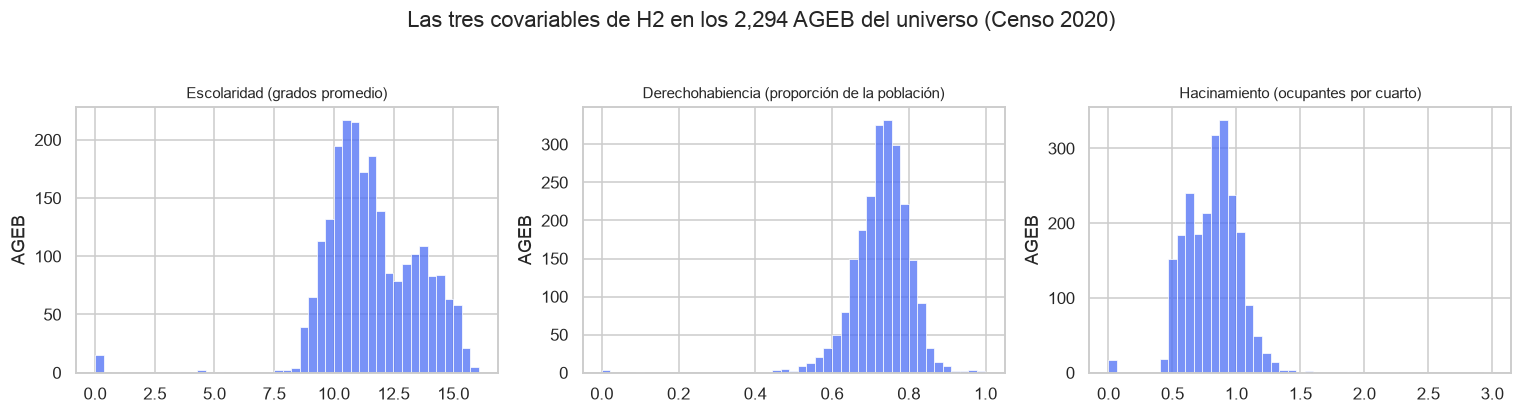

In [4]:
desc = cov.loc[cov["ageb"].isin(universo), COVS + ["VIVPAR_HAB", "POBTOT"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["faltantes"] = cov.loc[cov["ageb"].isin(universo), COVS + ["VIVPAR_HAB", "POBTOT"]].isna().sum()
display(desc)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
etiquetas = {"GRAPROES": "Escolaridad (grados promedio)",
             "pct_der_ss": "Derechohabiencia (proporción de la población)",
             "PRO_OCUP_C": "Hacinamiento (ocupantes por cuarto)"}
for ax, v in zip(axes, COVS):
    sns.histplot(cov.loc[cov["ageb"].isin(universo), v].dropna(), bins=45, ax=ax, color="#4c6ef5")
    ax.set_title(etiquetas[v], fontsize=10); ax.set_xlabel(""); ax.set_ylabel("AGEB")
fig.suptitle(f"Las tres covariables de H2 en los {len(universo):,} AGEB del universo (Censo 2020)", y=1.04)
plt.tight_layout(); plt.show()

## 4. Exclusiones de S5, y cuánta carpeta se va con ellas

Las exclusiones se fijaron en `PLAN_31_OCT.md` §3.3 **antes** de ver cualquier resultado. Son tres y cada una tiene su razón:

1. **Viviendas particulares habitadas en 0 o reservadas con `*`.** Sin denominador no hay tasa y, más importante, un AGEB sin viviendas habitadas no tiene hogares que las covariables puedan describir.
2. **Menos de 50 viviendas habitadas.** El 2.5 mostró que ahí la tasa llega a 7,250 carpetas por 1,000 viviendas contra un p99 de 44: son AGEB comerciales o institucionales donde el hecho ocurre pero la gente no vive.
3. **Covariable reservada por confidencialidad.** El `*` no se imputa; el AGEB sale.

Lo que hay que reportar no es el número de AGEB excluidos sino **la fracción de carpetas que se va con ellos**. Si fuera grande, las exclusiones estarían decidiendo el resultado.

In [5]:
u = cov[cov["ageb"].isin(universo)].copy()
carp_u = carp.loc[universo, VENT].sum(axis=1).rename("carpetas_2v")
u = u.merge(carp_u, left_on="ageb", right_index=True, how="left")

u["excl_sin_poligono"] = u["ageb"].isin(SIN_POLIGONO)
u["excl_viv_cero"]     = u["VIVPAR_HAB"].fillna(0).eq(0)
u["excl_viv_reserv"]   = u["VIVPAR_HAB"].isna()
u["excl_viv_menor50"]  = u["VIVPAR_HAB"].between(1, MIN_VIV - 1)
u["excl_cov_reserv"]   = u[COVS].isna().any(axis=1)
MOT = ["excl_sin_poligono", "excl_viv_cero", "excl_viv_reserv", "excl_viv_menor50", "excl_cov_reserv"]
u["excluido"] = u[MOT].any(axis=1)

tab = pd.DataFrame({
    "AGEB": [u[m].sum() for m in MOT] + [u["excluido"].sum()],
    "carpetas": [u.loc[u[m], "carpetas_2v"].sum() for m in MOT] + [u.loc[u["excluido"], "carpetas_2v"].sum()],
}, index=[m.replace("excl_", "") for m in MOT] + ["TOTAL (sin doble conteo)"])
tab["% de las carpetas del universo"] = tab["carpetas"] / u["carpetas_2v"].sum()
display(tab)

est = u[~u["excluido"]].copy()
print(f"universo primario:           {len(u):,} AGEB")
print(f"universo de estimación H2:   {len(est):,} AGEB  ({len(est)/len(u):.1%})")
print(f"carpetas conservadas:        {est['carpetas_2v'].sum():,.0f} de {u['carpetas_2v'].sum():,.0f}  ({est['carpetas_2v'].sum()/u['carpetas_2v'].sum():.2%})")
print(f"universo de estimación V1 (conteo alto): {est['ageb'].isin(alto).sum():,} AGEB")

,AGEB,carpetas,% de las carpetas del universo
sin_poligono,0,0,0.0000
viv_cero,25,249,0.0047
viv_reserv,10,77,0.0015
viv_menor50,19,229,0.0043
cov_reserv,22,272,0.0051
TOTAL (sin doble conteo),44,478,0.0090


universo primario:           2,294 AGEB
universo de estimación H2:   2,250 AGEB  (98.1%)
carpetas conservadas:        52,572 de 53,050  (99.10%)
universo de estimación V1 (conteo alto): 696 AGEB


## 5. Colinealidad entre covariables

Las tres covariables miden facetas de la misma cosa y por eso están correlacionadas. Esto hay que medirlo **antes** de la regresión, porque la regla del §3.4 depende de él: si algún VIF supera 5, el veredicto de H2 se lee sobre las tres regresiones de una sola covariable y no sobre la conjunta, y eso se declara.

Ojo con lo que **no** es esto: la matriz es entre covariables. No incluye la brecha.

In [6]:
corr = est[COVS].corr(method="pearson")
display(corr.rename(index=etiquetas, columns=etiquetas))

# VIF por la vía directa: 1/(1-R²) de cada covariable contra las otras dos
X = est[COVS].to_numpy(float)
X = (X - X.mean(0)) / X.std(0)
vif = {}
for j, v in enumerate(COVS):
    otros = np.delete(X, j, axis=1)
    A = np.column_stack([np.ones(len(otros)), otros])
    beta, *_ = np.linalg.lstsq(A, X[:, j], rcond=None)
    r2 = 1 - ((X[:, j] - A @ beta) ** 2).sum() / ((X[:, j] - X[:, j].mean()) ** 2).sum()
    vif[v] = 1 / (1 - r2)
vif = pd.Series(vif, name="VIF").to_frame()
vif["R² contra las otras dos"] = 1 - 1 / vif["VIF"]
display(vif)
print("VIF máximo:", f"{vif['VIF'].max():.2f}", "| regla: si > 5, el veredicto se lee sobre las tres regresiones simples (PLAN_31_OCT.md §3.4)")

,Escolaridad (grados promedio),Derechohabiencia (proporción de la población),Hacinamiento (ocupantes por cuarto)
Escolaridad (grados promedio),1.0000,0.5929,-0.9308
Derechohabiencia (proporción de la población),0.5929,1.0000,-0.6121
Hacinamiento (ocupantes por cuarto),-0.9308,-0.6121,1.0000


,VIF,R² contra las otras dos
GRAPROES,7.5361,0.8673
pct_der_ss,1.6095,0.3787
PRO_OCUP_C,7.8160,0.8721


VIF máximo: 7.82 | regla: si > 5, el veredicto se lee sobre las tres regresiones simples (PLAN_31_OCT.md §3.4)


## 6. Exportación: `12_ageb_covariables_resageburb.csv`

Una fila por AGEB del universo primario, con las covariables, el denominador, las banderas de exclusión y las dos columnas de universo (primario y conteo alto). El 3.1 lee este archivo y no vuelve a tocar RESAGEBURB.

In [7]:
exp = est_todo = u.copy()
exp["universo_primario"] = True
exp["universo_conteo_alto"] = exp["ageb"].isin(alto)
exp["universo_estimacion_h2"] = ~exp["excluido"]
exp["alcaldia"] = exp["ageb"].map(vf.drop_duplicates("ageb").set_index("ageb")["alcaldia"])

cols = (["ageb", "alcaldia", "carpetas_2v"] + COVS + ["PDER_SS", "POBTOT", "VIVPAR_HAB"]
        + MOT + ["excluido", "universo_primario", "universo_conteo_alto", "universo_estimacion_h2"])
exp = exp[cols].sort_values("ageb")
for c in COVS + ["carpetas_2v"]:
    exp[c] = exp[c].round(4)

ruta = OUT / "12_ageb_covariables_resageburb.csv"
exp.to_csv(ruta, index=False)
print("escrito:", ruta, exp.shape)
display(exp.head(8))
sorted(p.name for p in OUT.glob("*.csv"))

escrito: /Users/emilianosandoval/Documents/code/caso_titulacion/resultados/12_ageb_covariables_resageburb.csv (2294, 18)


,ageb,alcaldia,carpetas_2v,GRAPROES,pct_der_ss,PRO_OCUP_C,PDER_SS,POBTOT,VIVPAR_HAB,excl_sin_poligono,excl_viv_cero,excl_viv_reserv,excl_viv_menor50,excl_cov_reserv,excluido,universo_primario,universo_conteo_alto,universo_estimacion_h2
3,0900200010010,AZCAPOTZALCO,18,11.5200,0.8106,0.7800,"2,580.0000",3183,860.0000,False,False,False,False,False,False,True,False,True
30,0900200010025,AZCAPOTZALCO,7,10.7300,0.8132,0.7600,"4,548.0000",5593,"1,637.0000",False,False,False,False,False,False,True,False,True
82,090020001003A,AZCAPOTZALCO,15,10.5500,0.7877,0.7900,"3,336.0000",4235,"1,179.0000",False,False,False,False,False,False,True,False,True
116,0900200010044,AZCAPOTZALCO,23,11.0700,0.8188,0.7300,"3,904.0000",4768,"1,364.0000",False,False,False,False,False,False,True,False,True
163,0900200010097,AZCAPOTZALCO,14,11.7400,0.8208,0.6900,"1,786.0000",2176,590.0000,False,False,False,False,False,False,True,False,True
189,090020001010A,AZCAPOTZALCO,16,11.8000,0.8030,0.6600,"2,687.0000",3346,880.0000,False,False,False,False,False,False,True,False,True
228,0900200010114,AZCAPOTZALCO,50,11.2100,0.7777,0.8600,"7,673.0000",9866,"2,973.0000",False,False,False,False,False,False,True,True,True
280,0900200010129,AZCAPOTZALCO,46,12.4300,0.8415,0.7200,"4,799.0000",5703,"1,795.0000",False,False,False,False,False,False,True,True,True


['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '12_ageb_covariables_resageburb.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv',
 '16_h2_regresion_brecha_covariables.csv']

# Experimento 3.1 — la regresión de H2

A partir de aquí empieza el **3.1**, que es la prueba de H2 propiamente. Todo lo anterior (secciones 1–6) es el 2.2 y ya está exportado en `12_`; nada de lo que sigue lo modifica.

**La regla no se toca.** Está en `PLAN_31_OCT.md` §3, fijada el **16 de octubre de 2026**, antes de calcular cualquier coeficiente. Lo único que cambió desde entonces lo cambió el 2.2 *dentro* de la regla: el VIF de `GRAPROES` (7.54) y de `PRO_OCUP_C` (7.82) superó 5, así que se activó la cláusula del §3.4 y **el veredicto se lee sobre las tres regresiones de una sola covariable**, con la conjunta como referencia. Los tres signos predichos siguen siendo los mismos.

| Covariable | Signo predicho por H2 | Lectura |
|---|---|---|
| `GRAPROES` (escolaridad) | **negativo** | donde hay más escolaridad, menos brecha |
| `pct_der_ss` (derechohabiencia) | **negativo** | donde hay más derechohabiencia, menos brecha |
| `PRO_OCUP_C` (hacinamiento) | **positivo** | donde hay más hacinamiento, más brecha |

**Lo que se lee y no se recalcula:** la brecha, los conteos y los grupos de H3 salen de `11_`; el universo de estimación, las covariables y las banderas de exclusión de `12_`; el componente de varianza entre AGEB (σ̂²_AGEB) de `13_`; el diagnóstico espacial de `15_`. Lo único que se construye aquí son los **centroides** de los AGEB, que `11_`–`15_` no guardan, y que salen del shapefile proyectado a una CRS métrica.

## 7. Insumos del 3.1: el panel, σ̂²_AGEB y la geometría

**El panel.** Una fila por AGEB × ventana sobre el universo de estimación de `12_`: 2,250 AGEB × 2 ventanas = 4,500 observaciones. La variable dependiente es el **logit empírico** con corrección de 0.5, exactamente la escala que el 2.3 descompuso:

> y<sub>i,w</sub> = log( (llamadas<sub>i,w</sub> + 0.5) / (carpetas<sub>i,w</sub> + 0.5) ) &nbsp;&nbsp;·&nbsp;&nbsp; v<sub>i,w</sub> = 1/(llamadas<sub>i,w</sub> + 0.5) + 1/(carpetas<sub>i,w</sub> + 0.5)

*Por qué esta escala y no la razón cruda:* uso el logit empírico asumiendo que el ruido de conteo es binomial dado el total, porque en esa escala **la varianza del error de medición tiene forma cerrada** (v) y se puede meter en la ponderación en vez de ignorarla. Si el ruido fuera sobredisperso, v estaría subestimada y los AGEB chicos recibirían demasiado peso: por eso V4 (MCO sin pesos) está entre las sensibilidades fijadas.

**σ̂²_AGEB se lee de `13_`, no se vuelve a estimar.** Es la columna `var_unidad` de la fila `ventana == "ambas"` de cada variante, que es el componente **entre AGEB** del experimento 2.3. Cada variante usa el σ̂² de su propia fila, porque son universos y numeradores distintos:

| Variante | Fila de `13_` | σ̂²_AGEB |
|---|---|---|
| Primaria, V3, V4, V5, placebo | `principal: todas las llamadas, >= 1 carpeta por ventana` | 0.1016 |
| V1 (conteo alto) | `sensibilidad: solo AGEB con >= 12 carpetas por ventana` | 0.0942 |
| V2 (19% descontado) | `sensibilidad: 19% de robo descontado (S1)` | 0.1367 |

**La geometría.** Los centroides salen de `total.shp` del shapefile del Censo 2020 (EPSG:4326), **proyectado a EPSG:6372** (Lambert cónica conforme para México) antes de medir distancias, porque en grados un kilómetro no mide lo mismo en latitud que en longitud y el ancho de banda está fijado en kilómetros. Los 2 AGEB sin polígono ya salieron del universo en el 2.2.

*Supuesto de agregación espacial:* uso el centroide del polígono como la posición del AGEB asumiendo que a la escala que importa —1–2 km, la que midió el 2.5— un AGEB urbano de la CDMX es aproximadamente puntual. Si los AGEB fueran muy grandes o muy alargados (los hay en Milpa Alta y Tlalpan), la distancia entre centroides subestimaría la contigüidad real y el kernel incluiría menos vecinos de los que debería, es decir el error estándar quedaría **demasiado optimista** en esos casos; el contraste es V5, que no usa distancias sino bloques.

In [8]:
import tempfile
import geopandas as gpd
from scipy import sparse
from scipy.spatial import cKDTree

SHP_ZIP = ROOT / "AGEB" / "593c12fd-4ff0-47b4-ab98-f5e930afd0e9.zip"
CRS_M   = 6372          # Mexico ITRF2008 / LCC: metrica, para medir kilometros
BW      = 2000.0        # ancho de banda del kernel de Bartlett, en metros (PLAN_31_OCT.md 3.2)
B_REP   = 1000          # replicas de V5 y del placebo
SIGNO_PREDICHO = {"GRAPROES": -1, "pct_der_ss": -1, "PRO_OCUP_C": +1}

# --- el universo y las covariables se LEEN de 12_ ---
c12 = pd.read_csv(OUT / "12_ageb_covariables_resageburb.csv", dtype={"ageb": str})
uni12 = c12[c12["universo_estimacion_h2"]][["ageb", "alcaldia"] + COVS + ["universo_conteo_alto"]]
print("universo de estimacion leido de 12_:", len(uni12), "AGEB |", uni12["alcaldia"].nunique(), "alcaldias")

# --- sigma^2 entre AGEB: se LEE de 13_ ---
v13 = pd.read_csv(OUT / "13_variacion_brecha_ageb_vs_alcaldia.csv")
def sigma2_ageb(variante):
    f = v13[(v13["delito"] == "violencia_familiar") & (v13["variante"] == variante) & (v13["ventana"] == "ambas")]
    assert len(f) == 1, f"13_ no tiene una sola fila para: {variante}"
    return float(f["var_unidad"].iloc[0])
S2 = {"prin": sigma2_ageb("principal: todas las llamadas, >= 1 carpeta por ventana"),
      "alto": sigma2_ageb("sensibilidad: solo AGEB con >= 12 carpetas por ventana"),
      "s1":   sigma2_ageb("sensibilidad: 19% de robo descontado (S1)")}
print("sigma^2_AGEB leido de 13_:", {k: round(v, 4) for k, v in S2.items()})

# --- el diagnostico espacial que justifica el ancho de banda: se LEE de 15_ ---
d15 = pd.read_csv(OUT / "15_diagnostico_ageb.csv")
corr_banda = d15[d15["indicador"].str.contains("correlograma", case=False, na=False)][
    ["variante", "n_ageb", "valor", "valor_corregido"]]
display(corr_banda)
print("El kernel se corta en 2 km porque ahi el correlograma del 2.5 ya esta en cero (y en negativo).")

universo de estimacion leido de 12_: 2250 AGEB | 16 alcaldias
sigma^2_AGEB leido de 13_: {'prin': 0.1016, 'alto': 0.0942, 's1': 0.1367}


,variante,n_ageb,valor,valor_corregido
11,banda 0–1 km · residuos dentro de alcaldía,2277,0.0873,0.2237
12,banda 1–2 km · residuos dentro de alcaldía,2292,0.0319,0.0809
13,banda 2–4 km · residuos dentro de alcaldía,2292,-0.0038,-0.0096
14,banda 4–8 km · residuos dentro de alcaldía,2294,-0.0070,-0.0176
15,banda 8–16 km · residuos dentro de alcaldía,2294,0.0002,0.0005


El kernel se corta en 2 km porque ahi el correlograma del 2.5 ya esta en cero (y en negativo).


In [9]:
# --- el panel AGEB x ventana ---
pan = (vf[["ageb", "ventana", "llamadas", "carpetas", "llamadas_robo_desc_s1"]]
         .merge(uni12, on="ageb", how="inner")
         .query("ventana in @VENT")
         .sort_values(["ageb", "ventana"]).reset_index(drop=True))
# los 76+1 bloques contiguos de H3: se LEEN de 11_ (columna grupo_h3 de robo a conductor)
mapa_grupo = brecha[brecha["delito"] == "robo_conductor"].drop_duplicates("ageb").set_index("ageb")["grupo_h3"]
pan["grupo_h3"] = pan["ageb"].map(mapa_grupo)
assert pan["grupo_h3"].notna().all(), "hay AGEB del universo sin grupo de H3"
print("panel:", pan.shape, "| AGEB:", pan['ageb'].nunique(), "| ventanas:", sorted(pan['ventana'].unique()),
      "| bloques de H3 que cubren el universo:", pan['grupo_h3'].nunique())

# --- estandarizacion: media y DE del universo de estimacion primario, fijas para todas las variantes ---
MU, SD = uni12[COVS].mean(), uni12[COVS].std(ddof=0)
for c in COVS:
    pan["z_" + c] = (pan[c] - MU[c]) / SD[c]
display(pd.DataFrame({"media": MU, "DE": SD}).round(4))

# --- centroides metricos ---
with tempfile.TemporaryDirectory() as td:
    zipfile.ZipFile(SHP_ZIP).extractall(td)
    shp = gpd.read_file(str(next(p for p in Path(td).rglob("total.shp"))))
print("shapefile:", shp.shape, "| CRS:", shp.crs)
shp = shp[shp.geometry.notna()].to_crs(CRS_M)
_c = shp.set_index("ageb").geometry.centroid
XY = pd.DataFrame({"x": _c.x, "y": _c.y})
falta = set(pan["ageb"]) - set(XY.index)
print("AGEB del panel sin centroide:", len(falta))
assert not falta, "faltan centroides: no se puede medir el kernel espacial"

panel: (4500, 11) | AGEB: 2250 | ventanas: ['2019', '2021-22'] | bloques de H3 que cubren el universo: 77


,media,DE
GRAPROES,11.6882,1.7423
pct_der_ss,0.7302,0.0674
PRO_OCUP_C,0.8143,0.1891


shapefile: (2433, 34) | CRS: EPSG:4326
AGEB del panel sin centroide: 0


## 8. El estimador: MCP, errores tipo Conley y R² parcial

Tres piezas, todas fijadas en `PLAN_31_OCT.md` §3.2.

**(1) Mínimos cuadrados ponderados** con w<sub>i,w</sub> = 1/(σ̂²_AGEB + v<sub>i,w</sub>). Es la ponderación de una meta-regresión de efectos aleatorios: cada observación pesa el inverso de su varianza total, que es la suma de la varianza real entre AGEB (σ̂²_AGEB, que viene del 2.3) y el ruido de conteo conocido (v). *Supuesto:* la uso asumiendo que el ruido es binomial y que el componente residual es homogéneo entre AGEB; si hubiera sobredispersión, esta ponderación le daría demasiado peso a los AGEB chicos y **MCO sin pesos sería más apropiado** — por eso V4 está entre las sensibilidades y no como una nota al pie.

**(2) Errores estándar tipo Conley**, kernel de Bartlett, ancho de banda 2 km:

> V̂ = (X'WX)⁻¹ · [ Σ<sub>i</sub> Σ<sub>j</sub> K(d<sub>ij</sub>) w<sub>i</sub> w<sub>j</sub> e<sub>i</sub> e<sub>j</sub> x<sub>i</sub> x<sub>j</sub>' ] · (X'WX)⁻¹ · n/(n−k),&nbsp;&nbsp; K(d) = max(0, 1 − d/2 km)

El **agrupamiento por AGEB sale gratis**: las dos observaciones de un mismo AGEB están a distancia 0 entre sí, así que K = 1 y su covarianza entra completa. Se calcula agregando primero las contribuciones por AGEB y luego multiplicando por la matriz dispersa del kernel (2,250 × 2,250, ~89 mil elementos no nulos, 40 vecinos por AGEB en promedio), que es lo que hace que el placebo de 1,000 réplicas corra en segundos.

*Por qué 2 km y no otro número:* el correlograma del 2.5 pone el I de Moran de los residuos en 0.224 a 0–1 km, 0.081 a 1–2 km y **−0.010 a 2–4 km**. El ancho de banda cubre todo el rango donde hay dependencia y no más. *Si la dependencia llegara más lejos* de lo que midió el 2.5, estos errores estándar seguirían siendo demasiado optimistas; el contraste que no depende de esta elección es **V5** (bloques) y la prueba de si la cuenta es honesta es el **placebo P**.

**(3) R² parcial.** Para cada covariable, la reducción proporcional de la suma ponderada de residuos al cuadrado al agregarla al modelo que ya tiene el efecto fijo de ventana (y, en la conjunta, las otras dos covariables). **El R² no es el criterio** del veredicto y se declaró de antemano que iba a ser chico; se reporta para que el lector juzgue la magnitud.

In [10]:
def kernel_bartlett(agebs):
    # Matriz dispersa K(d) = max(0, 1 - d/BW) entre centroides, con diagonal 1 (agrupa por AGEB)
    P = XY.loc[list(agebs)].to_numpy(float)
    arbol = cKDTree(P)
    D = arbol.sparse_distance_matrix(arbol, BW, output_type="coo_matrix")
    K = sparse.coo_matrix((np.maximum(0.0, 1.0 - D.data / BW), (D.row, D.col)), shape=D.shape).tocsr()
    K.setdiag(1.0)
    return K.tocsr()

def matriz_diseno(df, cols, fe_alcaldia, Z_sustituto=None):
    if Z_sustituto is not None:
        Z = Z_sustituto
    elif cols:
        Z = df[["z_" + c for c in cols]].to_numpy(float)
    else:
        Z = np.zeros((len(df), 0))
    D = [(df["ventana"] == w).to_numpy(float) for w in VENT]          # efecto fijo de ventana
    if fe_alcaldia:                                                    # V3: + efecto fijo de alcaldia
        D += [(df["alcaldia"] == a).to_numpy(float) for a in sorted(df["alcaldia"].unique())[1:]]
    return np.column_stack([Z] + D)

def ajusta(df, s2a, cols, pesos=True, s1=False, fe_alcaldia=False, Z_sustituto=None):
    ll = df["llamadas"].to_numpy(float); car = df["carpetas"].to_numpy(float)
    num = ll - df["llamadas_robo_desc_s1"].to_numpy(float) if s1 else ll    # V2: numerador descontado
    y = np.log((num + 0.5) / (car + 0.5))
    v = 1.0 / (ll + 0.5) + 1.0 / (car + 0.5)                                # varianza binomial conocida
    w = 1.0 / (s2a + v) if pesos else np.ones(len(df))
    X = matriz_diseno(df, cols, fe_alcaldia, Z_sustituto)
    sw = np.sqrt(w)
    beta, *_ = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)
    return X, w, y - X @ beta, beta

def var_conley(X, w, e, idx_ageb, K, n_ageb):
    inv = np.linalg.pinv(X.T @ (X * w[:, None]))
    Ag = np.zeros((n_ageb, X.shape[1]))
    np.add.at(Ag, idx_ageb, X * (w * e)[:, None])       # suma por AGEB: K solo depende del par de AGEB
    Omega = Ag.T @ (K @ Ag)
    n, k = len(w), X.shape[1]
    return inv @ Omega @ inv * (n / (n - k))

def ssr_ponderada(w, e):
    return float((w * e ** 2).sum())

def corre(df, s2a, cols, nombre, pesos=True, s1=False, fe_alcaldia=False):
    A = sorted(df["ageb"].unique()); aix = {a: i for i, a in enumerate(A)}
    K = kernel_bartlett(A); idx = df["ageb"].map(aix).to_numpy()
    X, w, e, beta = ajusta(df, s2a, cols, pesos, s1, fe_alcaldia)
    V = var_conley(X, w, e, idx, K, len(A)); se = np.sqrt(np.diag(V))
    filas = []
    for j, c in enumerate(cols):
        _, w0, e0, _ = ajusta(df, s2a, [x for x in cols if x != c], pesos, s1, fe_alcaldia)
        s0, s1_ = ssr_ponderada(w0, e0), ssr_ponderada(w, e)
        filas.append(dict(especificacion=nombre, covariable=c, signo_predicho=SIGNO_PREDICHO[c],
                          beta=beta[j], se_espacial=se[j],
                          ic95_inf=beta[j] - 1.96 * se[j], ic95_sup=beta[j] + 1.96 * se[j],
                          t=beta[j] / se[j], razon_multiplicativa=np.exp(beta[j]),
                          r2_parcial=(s0 - s1_) / s0, metodo_ic="Conley Bartlett 2 km + AGEB",
                          n_obs=len(df), n_ageb=df["ageb"].nunique()))
    return pd.DataFrame(filas)

print("estimador listo | kernel de prueba:", kernel_bartlett(sorted(pan['ageb'].unique())).nnz, "elementos no nulos")

estimador listo | kernel de prueba: 89212 elementos no nulos


## 9. La especificación primaria

Primero las **tres regresiones de una sola covariable**, que es donde se lee el veredicto por la cláusula del §3.4, y después la **conjunta como referencia**.

Cada coeficiente se lee de dos formas, que son la misma: β es el cambio en **log-brecha por una desviación estándar** de la covariable, y e^β es el **factor multiplicativo** sobre la brecha. Una desviación estándar es 2.00 grados de escolaridad, 0.075 de proporción de derechohabiencia y 0.211 ocupantes por cuarto.

In [11]:
RES = []
for c in COVS:
    RES.append(corre(pan, S2["prin"], [c], "primaria simple"))
prim = pd.concat(RES, ignore_index=True)
display(prim.drop(columns=["metodo_ic"]).round(4))

,especificacion,covariable,signo_predicho,beta,se_espacial,ic95_inf,ic95_sup,t,razon_multiplicativa,r2_parcial,n_obs,n_ageb
0,primaria simple,GRAPROES,-1,-0.0410,0.0191,-0.0784,-0.0035,-2.1443,0.9599,0.0037,4500,2250
1,primaria simple,pct_der_ss,-1,-0.0393,0.0172,-0.0731,-0.0056,-2.2830,0.9614,0.0034,4500,2250
2,primaria simple,PRO_OCUP_C,1,0.0302,0.0177,-0.0046,0.0649,1.7025,1.0306,0.0020,4500,2250


**Interpretación de las tres simples.** Las dos covariables de signo negativo predicho lo tienen, con intervalos que excluyen el cero por poco: una desviación estándar más de escolaridad se asocia con una brecha **4.0% menor** (e^β = 0.960; IC 95% 0.925–0.997) y una desviación estándar más de derechohabiencia con una brecha **3.9% menor** (0.961; IC 0.930–0.994). El hacinamiento tiene el signo positivo que H2 predice —**+3.1%** por desviación estándar (1.031)— pero su intervalo incluye el cero (IC 0.995–1.067). Los tres R² parciales están **entre 0.002 y 0.004**, exactamente del orden que se declaró de antemano: el mosaico de barrio de 1–2 km no lo explican tres covariables de AGEB, y el criterio nunca fue el R².

In [12]:
conj = corre(pan, S2["prin"], COVS, "primaria conjunta (referencia)")
RES.append(conj)
display(conj.drop(columns=["metodo_ic"]).round(4))

,especificacion,covariable,signo_predicho,beta,se_espacial,ic95_inf,ic95_sup,t,razon_multiplicativa,r2_parcial,n_obs,n_ageb
0,primaria conjunta (referencia),GRAPROES,-1,-0.0927,0.0416,-0.1743,-0.0111,-2.2275,0.9115,0.0025,4500,2250
1,primaria conjunta (referencia),pct_der_ss,-1,-0.0309,0.0189,-0.0679,0.0062,-1.6336,0.9696,0.0014,4500,2250
2,primaria conjunta (referencia),PRO_OCUP_C,1,-0.0752,0.0391,-0.1518,0.0014,-1.9243,0.9276,0.0016,4500,2250


**Interpretación de la conjunta, y por qué es solo referencia.** Aquí se ve en vivo lo que el 2.2 anticipó: con `GRAPROES` y `PRO_OCUP_C` correlacionadas a **r = −0.93** (VIF 7.54 y 7.82), la conjunta **no puede separar escolaridad de hacinamiento**. El síntoma es que el coeficiente del hacinamiento **cambia de signo** (β = −0.075, e^β = 0.928) y los errores estándar se duplican respecto de las simples (0.042 contra 0.019 en escolaridad). Eso no es evidencia contra H2: es la aritmética de dos variables que miden el mismo eje al revés, y es la razón por la que la cláusula del §3.4 —escrita antes de calcular esto— manda leer el veredicto en las simples. La conjunta se reporta porque ocultarla sería peor, y se lee así: **el eje de carencia aparece, pero esta especificación no dice por cuál de sus dos caras.**

## 10. Las cinco sensibilidades

Fijadas el 16 de oct y todas reportadas, salga lo que salga. Lo que la regla del §3.4 pide de ellas es **que el signo se mantenga**, no que el intervalo excluya el cero: eso se le exige solo a la especificación primaria.

| # | Qué cambia | Qué pone a prueba |
|---|---|---|
| V1 | Solo los 696 AGEB de conteo alto (σ̂²_AGEB de su propia fila de `13_`) | Que no lo produzca el ruido de los AGEB chicos |
| V2 | Numerador con el 19% de robo descontado (S1) | Que no dependa de la contaminación del canal 911 |
| V3 | Más efecto fijo de alcaldía | Que la asociación exista **dentro** de la alcaldía. Es la más exigente |
| V4 | MCO sin pesos | Que no la produzca la ponderación |
| V5 | Bootstrap por bloques sobre los grupos contiguos de H3 | Un intervalo que no depende del kernel espacial |

In [13]:
alto = pan[pan["universo_conteo_alto"]].copy()
print("V1:", alto["ageb"].nunique(), "AGEB de conteo alto en el universo de estimacion")
SENSI = []
for c in COVS:
    SENSI.append(corre(alto, S2["alto"], [c], "V1 conteo alto"))
    SENSI.append(corre(pan,  S2["s1"],   [c], "V2 S1 19% descontado", s1=True))
    SENSI.append(corre(pan,  S2["prin"], [c], "V3 EF de alcaldia", fe_alcaldia=True))
    SENSI.append(corre(pan,  S2["prin"], [c], "V4 MCO sin pesos", pesos=False))
RES += SENSI
v14 = pd.concat(SENSI, ignore_index=True).sort_values(["covariable", "especificacion"])
display(v14[["especificacion", "covariable", "beta", "se_espacial", "ic95_inf", "ic95_sup",
             "t", "razon_multiplicativa", "r2_parcial", "n_ageb"]].round(4).to_string(index=False))

V1: 696 AGEB de conteo alto en el universo de estimacion


'      especificacion covariable    beta  se_espacial  ic95_inf  ic95_sup       t  razon_multiplicativa  r2_parcial  n_ageb\n      V1 conteo alto   GRAPROES -0.0614       0.0300   -0.1202   -0.0027 -2.0506                0.9404      0.0067     696\nV2 S1 19% descontado   GRAPROES -0.1897       0.0219   -0.2326   -0.1468 -8.6676                0.8272      0.0433    2250\n   V3 EF de alcaldia   GRAPROES -0.0482       0.0176   -0.0827   -0.0136 -2.7332                0.9530      0.0034    2250\n    V4 MCO sin pesos   GRAPROES -0.0731       0.0218   -0.1157   -0.0304 -3.3565                0.9295      0.0091    2250\n      V1 conteo alto PRO_OCUP_C  0.0328       0.0278   -0.0218    0.0873  1.1777                1.0333      0.0020     696\nV2 S1 19% descontado PRO_OCUP_C  0.1701       0.0206    0.1296    0.2105  8.2474                1.1854      0.0346    2250\n   V3 EF de alcaldia PRO_OCUP_C  0.0313       0.0157    0.0005    0.0620  1.9927                1.0318      0.0016    2250\n    V4 

**Interpretación de V1–V4, covariable por covariable.**

- **`GRAPROES`: el signo negativo se mantiene en las cuatro** (−0.061 en V1, −0.190 en V2, −0.048 en V3, −0.073 en V4) y en las cuatro el intervalo excluye el cero. Que sobreviva a **V3**, el efecto fijo de alcaldía, es lo que más dice: la asociación no es el gradiente centro–periferia disfrazado, existe **entre AGEB de la misma alcaldía**, que es precisamente el grano donde H1 encontró el 89% de la varianza.
- **`pct_der_ss`: el signo negativo se mantiene en V1, V2 y V4, pero en V3 se va a +0.002** (e^β = 1.002, IC 0.971–1.034). O sea: **toda la asociación de la derechohabiencia vive entre alcaldías, no dentro de ellas**. Con 16 alcaldías eso es muy poca información, y además es el gradiente centro–periferia que el caso ya documentó por otras vías. El signo cambia entre variantes y eso, por la regla, tiene consecuencia directa en el veredicto.
- **`PRO_OCUP_C`: el signo positivo se mantiene en las cuatro** (+0.033, +0.170, +0.031, +0.062), y en V2 y V4 el intervalo excluye el cero; en la primaria y en V1 no. El signo es estable; la precisión no alcanza.
- **Sobre V2.** Los coeficientes de V2 son de tres a cinco veces más grandes que los de la primaria en las tres covariables. Eso **no es que H2 se vea mejor ahí**: el descuento de S1 se reparte proporcionalmente a las carpetas de robo a casa habitación del AGEB, que son una variable con su propia estructura socioeconómica, así que V2 mete una covariable por la puerta de atrás. Sirve para lo que se fijó —**verificar el signo**— y no para medir magnitud.

In [14]:
# --- V5: bootstrap por bloques sobre los grupos contiguos de H3 ---
GRU = sorted(pan["grupo_h3"].unique())
idx_bloque = {g: pan.index[pan["grupo_h3"] == g].to_numpy() for g in GRU}
print(f"V5: {len(GRU)} bloques contiguos (los 76 de H3 que cumplen umbral + 1 que completa el universo);",
      f"mediana de {int(np.median([len(i) for i in idx_bloque.values()]))} observaciones por bloque")

rng = np.random.default_rng(SEMILLA)
boot = {c: np.empty(B_REP) for c in COVS}
for r in range(B_REP):
    pick = rng.integers(0, len(GRU), len(GRU))                  # bloques con reemplazo, mismo numero de bloques
    d = pan.loc[np.concatenate([idx_bloque[GRU[k]] for k in pick])]
    for c in COVS:
        boot[c][r] = ajusta(d, S2["prin"], [c])[3][0]

v5 = []
for c in COVS:
    a = boot[c]; lo, hi = np.percentile(a, [2.5, 97.5])
    v5.append(dict(especificacion="V5 bootstrap por bloques", covariable=c, signo_predicho=SIGNO_PREDICHO[c],
                   beta=float(np.median(a)), se_espacial=float(a.std(ddof=1)), ic95_inf=lo, ic95_sup=hi,
                   t=float(np.median(a) / a.std(ddof=1)), razon_multiplicativa=float(np.exp(np.median(a))),
                   r2_parcial=np.nan, metodo_ic=f"percentil bootstrap por bloques ({B_REP} replicas, semilla {SEMILLA})",
                   n_obs=len(pan), n_ageb=pan["ageb"].nunique(),
                   prop_signo_predicho=float(np.mean(np.sign(a) == SIGNO_PREDICHO[c]))))
v5 = pd.DataFrame(v5)
RES.append(v5)
display(v5[["covariable", "beta", "se_espacial", "ic95_inf", "ic95_sup", "razon_multiplicativa", "prop_signo_predicho"]].round(4))

V5: 77 bloques contiguos (los 76 de H3 que cumplen umbral + 1 que completa el universo); mediana de 42 observaciones por bloque


,covariable,beta,se_espacial,ic95_inf,ic95_sup,razon_multiplicativa,prop_signo_predicho
0,GRAPROES,-0.0416,0.0251,-0.0871,0.0104,0.9592,0.9400
1,pct_der_ss,-0.0384,0.0211,-0.0776,0.0034,0.9624,0.9630
2,PRO_OCUP_C,0.0299,0.0245,-0.0209,0.0752,1.0303,0.8740


**Interpretación de V5.** El bootstrap por bloques —que no supone nada sobre la forma del kernel, solo que los grupos contiguos de H3 son intercambiables— **mantiene los tres signos**: la mediana de las 1,000 réplicas es −0.042 para escolaridad, −0.038 para derechohabiencia y +0.030 para hacinamiento, con el signo predicho en el **94%, 96% y 87%** de las réplicas. Pero sus intervalos de percentil **incluyen el cero en las tres** (escolaridad −0.087 a +0.010). Eso hay que decirlo sin adornarlo: la precisión de la especificación primaria depende de la forma del kernel espacial, y con 77 bloques —no 2,250 AGEB— la información efectiva es mucho menor. La regla le pide a V5 el signo, y el signo está; la magnitud de la incertidumbre que V5 sugiere es parte del resultado.

## 11. El placebo espacial

Esto es lo que el 2.5 dejó como requisito. Con el I de Moran de los residuos en 0.097 (corregido 0.245), **un estadístico t grande contra una nula ingenua no significa nada**: la pregunta es si el t observado supera lo que produce el azar *cuando el azar conserva la estructura espacial*.

**Cómo se construye la nula, fijada el 16 de oct:** 1,000 permutaciones de las tres covariables **restringidas dentro de alcaldía** (semilla 2026), permutando los tres valores juntos para que la correlación entre covariables —y la composición socioeconómica de cada alcaldía— queden intactas. Lo que se destruye es solo la asignación fina de covariables a AGEB dentro de la alcaldía, que es justo la escala de 1–2 km donde vive el mosaico. Se guarda la distribución de |t| con los **mismos errores de Conley** y se compara contra el observado.

*Qué se compra con esta nula y qué no:* conserva el nivel de alcaldía, así que **no pone a prueba la parte de la asociación que vive entre alcaldías** — esa es la que V3 interroga. Lo que pone a prueba es si los errores estándar espaciales están contando bien la dependencia dentro de la alcaldía.

In [15]:
A = sorted(pan["ageb"].unique()); AIX = {a: i for i, a in enumerate(A)}
K_PRIN = kernel_bartlett(A); IDX_PRIN = pan["ageb"].map(AIX).to_numpy()

u_ageb = pan.drop_duplicates("ageb")[["ageb", "alcaldia"] + COVS].reset_index(drop=True)
Z_UNI = np.column_stack([(u_ageb[c].to_numpy(float) - MU[c]) / SD[c] for c in COVS])
POS = pan["ageb"].map({a: i for i, a in enumerate(u_ageb["ageb"])}).to_numpy()
BLOQ_ALC = [np.where(u_ageb["alcaldia"].to_numpy() == a)[0] for a in sorted(u_ageb["alcaldia"].unique())]
print("permutacion restringida:", len(BLOQ_ALC), "alcaldias |",
      "AGEB por alcaldia:", [len(b) for b in BLOQ_ALC])

t_obs = {}
for c in COVS:
    X, w, e, beta = ajusta(pan, S2["prin"], [c])
    t_obs[c] = beta[0] / np.sqrt(var_conley(X, w, e, IDX_PRIN, K_PRIN, len(A))[0, 0])

rng = np.random.default_rng(SEMILLA)
t_nula = {c: np.empty(B_REP) for c in COVS}
for r in range(B_REP):
    perm = np.arange(len(u_ageb))
    for b in BLOQ_ALC:
        perm[b] = rng.permutation(b)                    # permuta DENTRO de alcaldia
    Zp = Z_UNI[perm][POS]
    for j, c in enumerate(COVS):
        X, w, e, beta = ajusta(pan, S2["prin"], [c], Z_sustituto=Zp[:, [j]])
        t_nula[c][r] = beta[0] / np.sqrt(var_conley(X, w, e, IDX_PRIN, K_PRIN, len(A))[0, 0])

plac = []
for c in COVS:
    a = np.abs(t_nula[c]); to = abs(t_obs[c])
    plac.append(dict(especificacion="P placebo espacial", covariable=c, signo_predicho=SIGNO_PREDICHO[c],
                     beta=np.nan, se_espacial=np.nan, ic95_inf=np.nan, ic95_sup=np.nan,
                     t=t_obs[c], razon_multiplicativa=np.nan, r2_parcial=np.nan,
                     metodo_ic=f"permutacion dentro de alcaldia ({B_REP} replicas, semilla {SEMILLA})",
                     n_obs=len(pan), n_ageb=pan["ageb"].nunique(),
                     t_abs_observado=to, p95_nula_t_abs=float(np.percentile(a, 95)),
                     p_perm=float((np.sum(a >= to) + 1) / (B_REP + 1)),
                     supera_p95_nula=bool(to > np.percentile(a, 95))))
plac = pd.DataFrame(plac)
RES.append(plac)
display(plac[["covariable", "t_abs_observado", "p95_nula_t_abs", "p_perm", "supera_p95_nula"]].round(4))

permutacion restringida: 16 alcaldias | AGEB por alcaldia: [189, 98, 102, 149, 30, 142, 293, 105, 426, 51, 96, 36, 100, 186, 137, 110]


,covariable,t_abs_observado,p95_nula_t_abs,p_perm,supera_p95_nula
0,GRAPROES,2.1443,1.7971,0.0110,True
1,pct_der_ss,2.2830,3.9307,0.7602,False
2,PRO_OCUP_C,1.7025,1.7045,0.0529,False


**Interpretación del placebo, que es el resultado metodológico más importante de esta sección.**

- **`GRAPROES` pasa.** |t| = 2.14 contra un percentil 95 de la nula de **1.80**, con p de permutación **0.011**. La nula espacial es apenas más ancha que la normal (1.80 contra 1.96 — de hecho **más angosta**), así que para esta covariable los errores de Conley a 2 km están contando bien la dependencia.
- **`pct_der_ss` no pasa, y por mucho.** |t| = 2.28 contra un percentil 95 de la nula de **3.93**, con p de permutación **0.76**: tres de cada cuatro permutaciones producen un t más extremo que el observado. La lectura es nítida y es consistente con lo que mostró V3: la derechohabiencia varía sobre todo **entre alcaldías**, a escalas muy por encima de los 2 km del kernel, así que el error estándar de Conley a 2 km **subestima su incertidumbre** y su IC 95% nominal es ilusorio. No es que el coeficiente sea cero: es que con esta especificación no se puede distinguir de cero.
- **`PRO_OCUP_C` queda en el filo.** |t| = 1.70 contra un percentil 95 de **1.70**, p = 0.053. No supera, y tampoco contradice: es exactamente lo mismo que dice su intervalo, que roza el cero.

*Lo que el placebo no es:* no es una prueba de H2 ni entra en la regla del §3.4, que se decidió sobre signo, intervalo primario y estabilidad. Es una **auditoría del error estándar**, y en un caso de tres la auditoría sale mal. Esa es información que cambia cómo se lee el veredicto, y por eso se reporta junto a él y no en un anexo.

## 12. Veredicto, aplicando la regla del §3.4 covariable por covariable

La regla, copiada de `PLAN_31_OCT.md` §3.4 sin modificarla:

> - **Se acepta** para esa covariable si (a) el signo de β es el predicho, (b) el IC 95% con errores espaciales **excluye el cero** en la especificación primaria, y (c) el signo se mantiene en **las cinco sensibilidades**.
> - **Se rechaza** si el intervalo excluye el cero **con el signo contrario** al predicho.
> - **No concluye** si el intervalo incluye el cero **o** si el signo cambia entre sensibilidades.

Por la cláusula de colinealidad, la "especificación primaria" de cada covariable es su **regresión de una sola covariable**. Las tres condiciones se evalúan en código, no a ojo.

In [16]:
T = pd.concat(RES, ignore_index=True)
SENS = ["V1 conteo alto", "V2 S1 19% descontado", "V3 EF de alcaldia", "V4 MCO sin pesos", "V5 bootstrap por bloques"]

ver = []
for c in COVS:
    s = SIGNO_PREDICHO[c]
    p = T[(T["covariable"] == c) & (T["especificacion"] == "primaria simple")].iloc[0]
    a = np.sign(p["beta"]) == s
    b_pred = (p["ic95_inf"] > 0) if s > 0 else (p["ic95_sup"] < 0)
    b_contra = (p["ic95_sup"] < 0) if s > 0 else (p["ic95_inf"] > 0)
    sens = T[(T["covariable"] == c) & (T["especificacion"].isin(SENS))]
    signos = dict(zip(sens["especificacion"], np.sign(sens["beta"]).astype(int)))
    cc = all(v == s for v in signos.values())
    veredicto = "acepta" if (a and b_pred and cc) else ("rechaza" if b_contra else "no concluye")
    motivo = ("(a) signo + (b) IC excluye el cero + (c) signo estable en las cinco sensibilidades" if veredicto == "acepta"
              else "(b) el IC primario excluye el cero con el signo contrario" if veredicto == "rechaza"
              else " y ".join([t for t in [None if b_pred else "(b) el IC primario incluye el cero",
                                           None if cc else "(c) el signo cambia entre sensibilidades"] if t]))
    pl = T[(T["covariable"] == c) & (T["especificacion"] == "P placebo espacial")].iloc[0]
    ver.append(dict(covariable=c, signo_predicho=s, beta=p["beta"], razon=np.exp(p["beta"]),
                    ic95_inf=p["ic95_inf"], ic95_sup=p["ic95_sup"], r2_parcial=p["r2_parcial"],
                    cond_a_signo=a, cond_b_ic=b_pred, cond_c_sensibilidades=cc,
                    signos_sensibilidades="".join("+" if v > 0 else "-" for v in [signos[k] for k in SENS]),
                    placebo_supera_p95=pl["supera_p95_nula"], placebo_p=pl["p_perm"],
                    VEREDICTO=veredicto, motivo=motivo))
VER = pd.DataFrame(ver)
display(VER[["covariable", "signo_predicho", "beta", "razon", "ic95_inf", "ic95_sup",
             "cond_a_signo", "cond_b_ic", "cond_c_sensibilidades", "signos_sensibilidades",
             "placebo_supera_p95", "placebo_p", "VEREDICTO"]].round(4).to_string(index=False))
for _, r in VER.iterrows():
    print(f"\n{r['covariable']}: H2 {r['VEREDICTO'].upper()} — {r['motivo']}")

'covariable  signo_predicho    beta  razon  ic95_inf  ic95_sup  cond_a_signo  cond_b_ic  cond_c_sensibilidades signos_sensibilidades  placebo_supera_p95  placebo_p   VEREDICTO\n  GRAPROES              -1 -0.0410 0.9599   -0.0784   -0.0035          True       True                   True                 -----                True     0.0110      acepta\npct_der_ss              -1 -0.0393 0.9614   -0.0731   -0.0056          True       True                  False                 --+--               False     0.7602 no concluye\nPRO_OCUP_C               1  0.0302 1.0306   -0.0046    0.0649          True      False                   True                 +++++               False     0.0529 no concluye'


GRAPROES: H2 ACEPTA — (a) signo + (b) IC excluye el cero + (c) signo estable en las cinco sensibilidades

pct_der_ss: H2 NO CONCLUYE — (c) el signo cambia entre sensibilidades

PRO_OCUP_C: H2 NO CONCLUYE — (b) el IC primario incluye el cero


### El veredicto en palabras

| Covariable | Veredicto | Por qué |
|---|---|---|
| **`GRAPROES`** escolaridad | **H2 se acepta** | Signo negativo como se predijo; IC 95% espacial 0.925–0.997 en razón multiplicativa, excluye el cero; signo estable en las cinco sensibilidades, **incluido el efecto fijo de alcaldía**; y el placebo espacial la respalda (p = 0.011) |
| **`pct_der_ss`** derechohabiencia | **H2 no concluye** | Falla (c): el signo **cambia** al meter efecto fijo de alcaldía (−0.039 → +0.002). Y el placebo lo confirma desde el otro lado: p95 de la nula espacial 3.93 contra un \|t\| observado de 2.28, p = 0.76 — su asociación vive entre alcaldías, donde hay 16 unidades, no 2,250 |
| **`PRO_OCUP_C`** hacinamiento | **H2 no concluye** | Falla (b): el signo positivo es el predicho y se mantiene en las cinco sensibilidades, pero el IC 95% primario incluye el cero (0.995–1.067) y el placebo queda en el filo (p = 0.053) |

**Lo que esto quiere decir, con el lenguaje que corresponde.** En violencia familiar, la brecha entre el aviso al 911 y la carpeta **se asocia negativamente con la escolaridad del AGEB**: una desviación estándar más de escolaridad (1.74 grados, la DE del universo de estimación) se asocia con una brecha aproximadamente **4% menor**, y esa asociación persiste al comparar únicamente AGEB de la misma alcaldía. La magnitud es pequeña y el R² parcial es de 0.004, lo que ya se había declarado de antemano: tres covariables de AGEB no explican un mosaico de barrio de 1–2 km. Nada de esto estima el subregistro ni afirma causalidad: **acota** en qué dirección se mueve la fricción entre el aviso y la denuncia a lo largo del territorio.

**La precaución que no se puede omitir, y es consecuencia del 2.2.** `GRAPROES` y `PRO_OCUP_C` son el **mismo eje medido al revés** (r = −0.93). Que la escolaridad acepte y el hacinamiento no concluya **no son dos resultados independientes**: son la misma asociación vista por sus dos caras, y la cara de la escolaridad resulta ser la que se mide con menos ruido. Lo honesto es decir que **el eje de carencia aparece en la dirección que H2 predijo, y lo hace con el signo estable y con el intervalo justo del lado correcto del cero**; y que de las tres predicciones originales de H2, **una se sostiene, dos no concluyen, y ninguna se rechaza**.

**Lo que H2 sigue sin poder decir**, igual que estaba escrito antes de verla (§3.6): no es inferencia individual (S5); no separa la propensión a *llamar* de la propensión a *denunciar* (S6), y si la escolaridad moviera la primera, el coeficiente estaría midiendo las dos cosas a la vez; y no es causal.

## 13. Exportación: `16_h2_regresion_brecha_covariables.csv`

Una fila por **covariable × especificación**: las tres simples de la primaria, las tres de la conjunta de referencia, las de V1–V4 con sus errores espaciales, las de V5 con su intervalo de percentil y las del placebo con su nula. Más las tres filas de veredicto, marcadas con `especificacion = "VEREDICTO"`, para que la tabla se pueda leer sin el notebook.

In [17]:
cols = ["especificacion", "covariable", "signo_predicho", "beta", "se_espacial", "ic95_inf", "ic95_sup",
        "t", "razon_multiplicativa", "r2_parcial", "metodo_ic", "n_obs", "n_ageb",
        "prop_signo_predicho", "t_abs_observado", "p95_nula_t_abs", "p_perm", "supera_p95_nula"]
T = T.reindex(columns=cols)

VX = VER.rename(columns={"razon": "razon_multiplicativa", "VEREDICTO": "veredicto"}).copy()
VX["especificacion"] = "VEREDICTO"
VX["metodo_ic"] = "regla PLAN_31_OCT.md 3.4, fijada el 16 oct 2026"
VX["n_obs"], VX["n_ageb"] = len(pan), pan["ageb"].nunique()
VX = VX.reindex(columns=cols + ["cond_a_signo", "cond_b_ic", "cond_c_sensibilidades",
                                "signos_sensibilidades", "placebo_supera_p95", "placebo_p",
                                "veredicto", "motivo"])

ORD = {"primaria simple": 0, "primaria conjunta (referencia)": 1, "V1 conteo alto": 2,
       "V2 S1 19% descontado": 3, "V3 EF de alcaldia": 4, "V4 MCO sin pesos": 5,
       "V5 bootstrap por bloques": 6, "P placebo espacial": 7, "VEREDICTO": 8}
S16 = pd.concat([T, VX], ignore_index=True)
S16["_o"] = S16["especificacion"].map(ORD)
S16["_c"] = S16["covariable"].map({c: i for i, c in enumerate(COVS)})
S16 = S16.sort_values(["_o", "_c"]).drop(columns=["_o", "_c"])
for c in S16.columns:
    if S16[c].dtype.kind == "f":
        S16[c] = S16[c].round(4)

ruta = OUT / "16_h2_regresion_brecha_covariables.csv"
S16.to_csv(ruta, index=False)
print("escrito:", ruta, S16.shape)
display(S16.head(12))
sorted(p.name for p in OUT.glob("*.csv"))

escrito: /Users/emilianosandoval/Documents/code/caso_titulacion/resultados/16_h2_regresion_brecha_covariables.csv (27, 26)


,especificacion,covariable,signo_predicho,beta,se_espacial,ic95_inf,ic95_sup,t,razon_multiplicativa,r2_parcial,metodo_ic,n_obs,n_ageb,prop_signo_predicho,t_abs_observado,p95_nula_t_abs,p_perm,supera_p95_nula,cond_a_signo,cond_b_ic,cond_c_sensibilidades,signos_sensibilidades,placebo_supera_p95,placebo_p,veredicto,motivo
0,primaria simple,GRAPROES,-1,-0.0410,0.0191,-0.0784,-0.0035,-2.1443,0.9599,0.0037,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,primaria simple,pct_der_ss,-1,-0.0393,0.0172,-0.0731,-0.0056,-2.2830,0.9614,0.0034,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,primaria simple,PRO_OCUP_C,1,0.0302,0.0177,-0.0046,0.0649,1.7025,1.0306,0.0020,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,primaria conjunta (referencia),GRAPROES,-1,-0.0927,0.0416,-0.1743,-0.0111,-2.2275,0.9115,0.0025,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,primaria conjunta (referencia),pct_der_ss,-1,-0.0309,0.0189,-0.0679,0.0062,-1.6336,0.9696,0.0014,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,primaria conjunta (referencia),PRO_OCUP_C,1,-0.0752,0.0391,-0.1518,0.0014,-1.9243,0.9276,0.0016,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,V1 conteo alto,GRAPROES,-1,-0.0614,0.0300,-0.1202,-0.0027,-2.0506,0.9404,0.0067,Conley Bartlett 2 km + AGEB,1392,696,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,V1 conteo alto,pct_der_ss,-1,-0.0452,0.0236,-0.0916,0.0011,-1.9146,0.9558,0.0054,Conley Bartlett 2 km + AGEB,1392,696,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,V1 conteo alto,PRO_OCUP_C,1,0.0328,0.0278,-0.0218,0.0873,1.1777,1.0333,0.0020,Conley Bartlett 2 km + AGEB,1392,696,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,V2 S1 19% descontado,GRAPROES,-1,-0.1897,0.0219,-0.2326,-0.1468,-8.6676,0.8272,0.0433,Conley Bartlett 2 km + AGEB,4500,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '12_ageb_covariables_resageburb.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv',
 '16_h2_regresion_brecha_covariables.csv']

## 14. Qué queda cerrado y qué sigue

**D4 queda cerrado.** H1 aceptada (2.3), H3 aceptada (2.4), el diagnóstico espacial hecho (2.5) y **H2 resuelta con su regla pre-registrada**: una covariable acepta, dos no concluyen, ninguna se rechaza. Los supuestos no se declararon, se **verificaron**: la autocorrelación se midió antes (2.5) y determinó el ancho de banda; el error de medición es conocido en forma cerrada y entra en la ponderación; y el placebo espacial auditó los errores estándar, con el resultado incómodo de que para la derechohabiencia **no** aguantan.

**Lo que cambia para el deck (slide 14) y para el escrito (§4):** H2 se presenta como *una de las tres predicciones se sostiene*, con la aclaración de que escolaridad y hacinamiento son un solo eje. La frase que se puede defender es "la brecha **se asocia** con la escolaridad del territorio, también dentro de la misma alcaldía, y la magnitud es pequeña"; la que no se puede defender es cualquier versión que hable de explicar o estimar el subregistro.

**Lo que sigue:** el **3.2** (19 de oct) hace las tres figuras —coeficientes estandarizados con IC espaciales, dispersión parcial de `GRAPROES`, que es la covariable que resultó informativa, y mapa de residuos— y con eso se **congelan las cifras**. Después de esa fecha no se corre ningún análisis nuevo: solo app (D5), escrito (D8) y deck (D6).

# Experimento 3.2 — las tres figuras de H2

**Producción de figura, no análisis nuevo.** Esta parte **no estima ningún coeficiente, no corre ninguna especificación nueva y no reabre el veredicto**. Todo lo que se dibuja ya está calculado: los β, los errores espaciales, los IC 95%, los R² parciales, el placebo y el veredicto se **leen de `resultados/16_`**; la brecha y los conteos de `11_`; el universo de estimación y las covariables de `12_`. Los residuos y el panel reutilizan `pan` y `ajusta()` tal como quedaron en la sección 8 —misma y, mismos pesos, mismo σ̂²_AGEB leído de `13_`—, sin redefinir el estimador ni cambiar la escala. Los polígonos salen del mismo shapefile que ya está cargado en la sección 7.

**Qué tiene que lograr cada figura**, que es lo que fija `PLAN_31_OCT.md` §3.7:

| Figura | Dónde va | La frase que tiene que sostener sin que nadie la explique en voz alta |
|---|---|---|
| `3.2_coeficientes_h2.png` | Slide 14 y tercera figura del escrito | De las tres predicciones de signo de H2, **una se sostiene, dos no concluyen, ninguna se rechaza** — y el intervalo de la derechohabiencia es **ilusorio** según el placebo espacial |
| `3.2_dispersion_parcial_escolaridad.png` | Respaldo del deck y apoyo del §4 del escrito | La pendiente de la escolaridad **es real y es chica**: existe y se ve, y no explica el mapa |
| `3.2_mapa_residuos_h2.png` | Respaldo, al lado del mapa hero | Lo que la covariable **no** explica: el mosaico de 1–2 km sigue entero después de quitar la escolaridad |

**Sin CSV nuevo.** El 3.2 no exporta tablas: `16_` ya tiene todas las cifras que estas figuras imprimen.

## 15. Las reglas de forma, declaradas antes de dibujar

Misma disciplina que la ventana del acercamiento del 2.6 (§10.5 de `build_eda2.py`): las decisiones de forma que no son obvias se fijan **antes** de mirar cómo queda la figura, para que el resultado no elija la presentación.

| Decisión | Regla fija | Supuesto, en el formato del criterio transversal |
|---|---|---|
| **Eje de la figura 1** | Razón multiplicativa e^β en escala logarítmica, con el **1.0** marcado con línea llena; los límites cubren todos los intervalos dibujados —incluidos los del placebo— más 10% de margen | *Uso e^β en log asumiendo que la cantidad que importa es el cambio **proporcional** de la brecha por desviación estándar, que es la escala en la que se estimó (log-brecha) y la misma del mapa.* Si la lectura que importara fuera el β en log, el eje lineal en β sería más apropiado, pero entonces el 1.0 —el "no hay asociación"— dejaría de ser el ancla visual. |
| **Cómo se marca que un IC es ilusorio** | Detrás del IC de Conley se dibuja en gris el **intervalo implícito por la nula del placebo**: β ± t\*₉₅·SE, con t\*₉₅ el percentil 95 de \|t\| de las 1,000 permutaciones restringidas dentro de alcaldía. Donde t\*₉₅ > 1.96 el intervalo nominal es **más angosto de lo que la nula espacial permite**, y se lee como ilusorio | *Uso el percentil 95 de la nula como valor crítico asumiendo que la permutación dentro de alcaldía reproduce la dependencia espacial relevante a la escala de 1–2 km del 2.5.* Si la dependencia que importara viviera **entre** alcaldías, esta nula la conserva y por lo tanto no la pone a prueba — eso lo interroga V3, no el placebo. Los tres valores de t\*₉₅ (1.80 / 3.93 / 1.70) salen de `16_`, no se recalculan. |
| **Puntos de la figura 2** | **Veintiles** (20 bins de igual número de observaciones) de la covariable residualizada, con medias ponderadas y barra de error de ±1.96 EE ponderado, encima de las 4,500 observaciones en tinta clara | *Elijo veintiles y no deciles asumiendo que con 4,500 observaciones conviene el mayor número de bins que deje cada uno con más de 200 observaciones (225), para ver la forma de la relación sin volver los puntos tan ruidosos como las observaciones individuales.* Con deciles la figura diría lo mismo con la mitad de resolución; con centiles los puntos volverían a ser una mancha. |
| **Ventana vertical de la figura 2** | ±2.5 desviaciones estándar ponderadas del residuo, simétrica, y se reporta cuántas observaciones quedan fuera | *Fijo la ventana con la dispersión del propio residuo asumiendo que la figura tiene que mostrar la nube donde está, no sus colas.* Si se recortara por percentiles del eje y, la pendiente dibujada y la estimada dejarían de corresponder visualmente. |
| **Escala de la figura 3** | **La misma del mapa hero del 2.6**: divergente en log, centrada en cero, límites ±2σ_AGEB = ×1.89 / ×0.53, con σ_AGEB leído de `13_`. Misma paleta, mismo tratamiento de los AGEB sin dato (gris) | *Uso exactamente la escala del mapa hero asumiendo que el punto de esta figura es la **comparación** con él: si la escala cambiara, un mosaico que sigue igual podría parecer que se aplanó, o al revés.* Las dos figuras están hechas para ponerse una al lado de la otra. |
| **Cifras impresas** | Regla del deck: **ninguna figura principal imprime más de tres cifras** en el cuerpo. Figura 1: las tres razones e^β. Figura 2: la pendiente y su R² parcial. Figura 3: ninguna, solo los valores de la escala. Todo lo demás vive en el pie | *Asumo que una slide se lee en 10 segundos y que los intervalos, los t y los p se defienden en voz alta o en el respaldo, no se leen del proyector.* |

**El verbo, en las tres.** Se **asocia**, **acota**, **aproxima**. Ninguna figura dice que la escolaridad explique, cause o estime el subregistro.

**Y la cautela que no se puede omitir, que va en el pie de la figura 1.** `GRAPROES` y `PRO_OCUP_C` son el **mismo eje medido al revés** (r = −0.93, VIF 7.54 y 7.82, del 2.2). La figura 1 muestra tres renglones pero **no son tres pruebas independientes**: son dos ejes, el de carencia —con la escolaridad y el hacinamiento como sus dos caras— y la derechohabiencia.

In [18]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIG = OUT / "figuras"; FIG.mkdir(exist_ok=True)
DPI = 200                                    # mismo dpi que el 2.6: legible en proyector

# --- paleta y tipografía: las mismas de build_eda2.py 10.5, para que las figuras se puedan mezclar ---
CMAP = LinearSegmentedColormap.from_list("brecha", ["#0d366b", "#256abf", "#86b6ef", "#cde2fb", "#f0efec",
                                                    "#fbd6d3", "#f0a39f", "#e34948", "#8f2322"])
GRIS, TINTA, TINTA2 = "#d9d7d2", "#1a1a19", "#56544f"
AZUL, ROJO, HUMO = "#256abf", "#e34948", "#b8b5ae"
ESTILO = {"font.size": 13, "hatch.linewidth": 0.45, "figure.facecolor": "white", "savefig.facecolor": "white"}

# --- la escala del mapa hero: sigma entre AGEB, LEIDO de 13_ via S2 (seccion 7) ---
SD_AGEB = float(np.sqrt(S2["prin"])); LIM = 2 * SD_AGEB
NORM = Normalize(-LIM, LIM)
print(f"escala del mapa hero reproducida: sigma_AGEB = {SD_AGEB:.4f} -> +-2 sigma = x{np.exp(LIM):.2f} / x{np.exp(-LIM):.2f}")

# --- todas las cifras del 3.1 se LEEN de 16_: aqui no se estima nada ---
r16 = pd.read_csv(OUT / "16_h2_regresion_brecha_covariables.csv")
PRIM16 = r16[r16["especificacion"] == "primaria simple"].set_index("covariable")
PLAC16 = r16[r16["especificacion"] == "P placebo espacial"].set_index("covariable")
VER16  = r16[r16["especificacion"] == "VEREDICTO"].set_index("covariable")
display(pd.DataFrame({
    "beta": PRIM16["beta"], "e^beta": PRIM16["razon_multiplicativa"],
    "ic95_inf": PRIM16["ic95_inf"], "ic95_sup": PRIM16["ic95_sup"], "se": PRIM16["se_espacial"],
    "r2_parcial": PRIM16["r2_parcial"], "t_obs": PLAC16["t_abs_observado"],
    "t95_nula": PLAC16["p95_nula_t_abs"], "p_placebo": PLAC16["p_perm"],
    "veredicto": VER16["veredicto"]}).loc[COVS])

ETIQ = {"GRAPROES": "Escolaridad", "pct_der_ss": "Derechohabiencia", "PRO_OCUP_C": "Hacinamiento"}
# la glosa de unidades NO se teclea: sale de la misma SD con que la seccion 7 estandarizo (universo de
# estimacion, 2,250 AGEB). Escrita a mano traia la DE del universo primario y la figura contradecia a 16_
UNID = {"GRAPROES":   f"1 DE = {SD['GRAPROES']:.2f} grados promedio",
        "pct_der_ss": f"1 DE = {100 * SD['pct_der_ss']:.1f} puntos de la población",
        "PRO_OCUP_C": f"1 DE = {SD['PRO_OCUP_C']:.2f} ocupantes por cuarto"}
print("glosa de unidades derivada de la estandarizacion del 3.1:", list(UNID.values()))
print("insumos listos | ninguna cifra de esta sección se recalcula: todas salen de 16_, 11_, 12_ y 13_")

escala del mapa hero reproducida: sigma_AGEB = 0.3187 -> +-2 sigma = x1.89 / x0.53


,beta,e^beta,ic95_inf,ic95_sup,se,r2_parcial,t_obs,t95_nula,p_placebo,veredicto
covariable,,,,,,,,,,
GRAPROES,-0.0410,0.9599,-0.0784,-0.0035,0.0191,0.0037,2.1443,1.7971,0.0110,acepta
pct_der_ss,-0.0393,0.9614,-0.0731,-0.0056,0.0172,0.0034,2.2830,3.9307,0.7602,no concluye
PRO_OCUP_C,0.0302,1.0306,-0.0046,0.0649,0.0177,0.0020,1.7025,1.7045,0.0529,no concluye


glosa de unidades derivada de la estandarizacion del 3.1: ['1 DE = 1.74 grados promedio', '1 DE = 6.7 puntos de la población', '1 DE = 0.19 ocupantes por cuarto']
insumos listos | ninguna cifra de esta sección se recalcula: todas salen de 16_, 11_, 12_ y 13_


### 15.1 Figura 1 — los tres coeficientes con su IC espacial y el IC que permite la nula

Es la figura de la **slide 14** y la tercera del escrito. Un renglón por covariable, en el eje de razón multiplicativa con el 1.0 marcado: a la izquierda el signo que H2 predijo, en el centro el intervalo, y a la derecha el veredicto. El intervalo gris de atrás es el que permite la nula espacial del placebo, y es lo que hace visible —sin explicarlo— que el de la derechohabiencia es ilusorio.

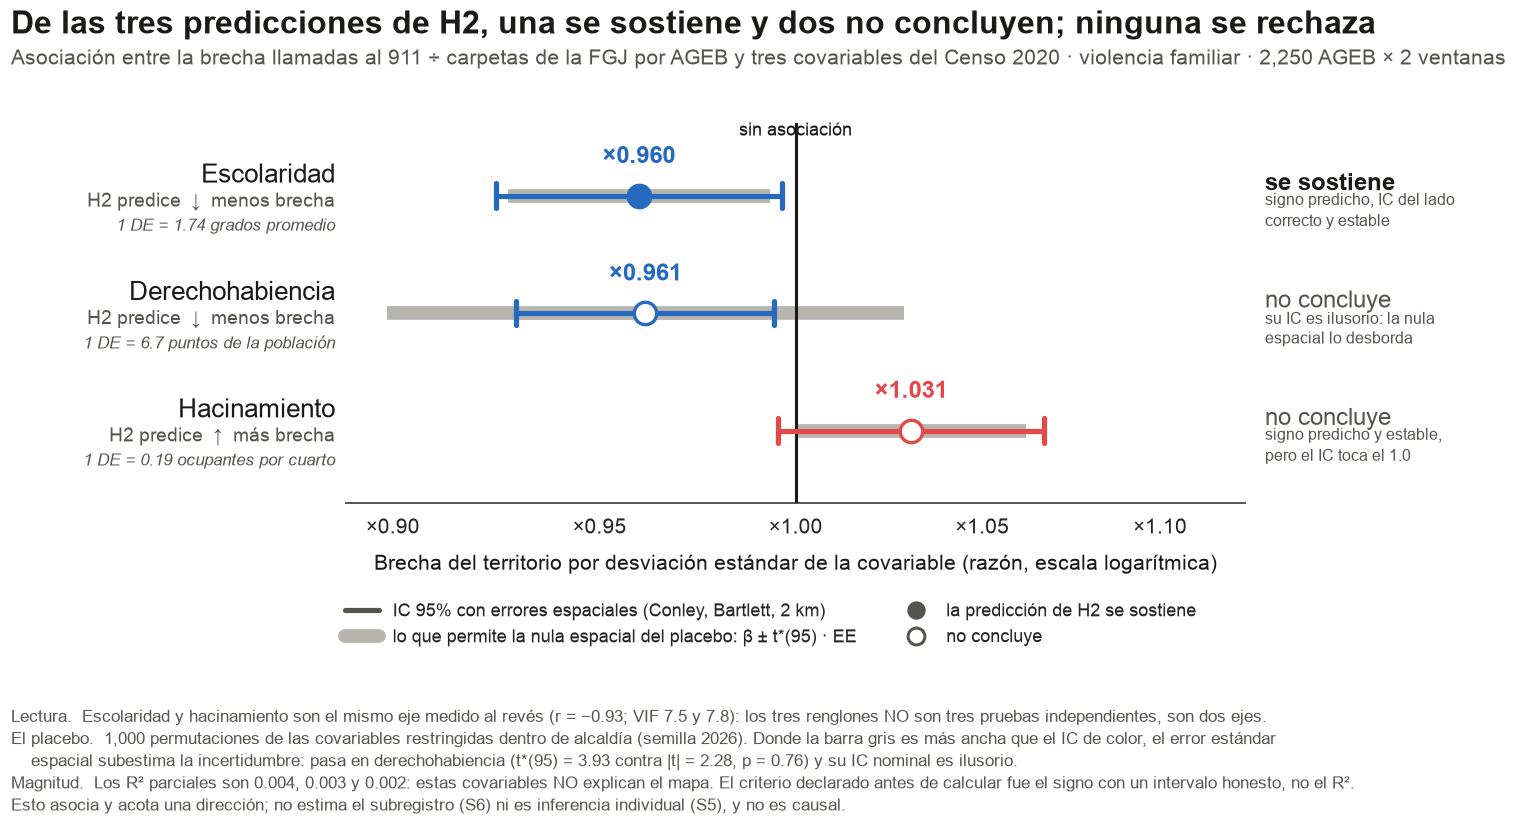

In [19]:
with mpl.rc_context(ESTILO):
    fig = plt.figure(figsize=(15.0, 7.6))
    ax = fig.add_axes([.215, .375, .545, .455])

    FLE = {-1: "H2 predice  ↓  menos brecha", +1: "H2 predice  ↑  más brecha"}
    xs = []
    for k, c in enumerate(COVS):
        yy = len(COVS) - 1 - k
        p, pl, vv = PRIM16.loc[c], PLAC16.loc[c], VER16.loc[c]
        b, se = float(p["beta"]), float(p["se_espacial"])
        t95 = float(pl["p95_nula_t_abs"])
        col = AZUL if b < 0 else ROJO
        acepta = str(vv["veredicto"]) == "acepta"

        # (1) atras: el intervalo implicito por la nula del placebo, beta +- t*_95 * SE
        lo_p, hi_p = np.exp(b - t95 * se), np.exp(b + t95 * se)
        ax.plot([lo_p, hi_p], [yy, yy], color=HUMO, lw=9, solid_capstyle="butt", zorder=2)
        # (2) encima: el IC 95% con errores espaciales de Conley, leido de 16_
        lo, hi = np.exp(float(p["ic95_inf"])), np.exp(float(p["ic95_sup"]))
        ax.plot([lo, hi], [yy, yy], color=col, lw=3.4, solid_capstyle="butt", zorder=4)
        for x in (lo, hi):
            ax.plot([x, x], [yy - .105, yy + .105], color=col, lw=3.4, zorder=4)
        ax.scatter([np.exp(b)], [yy], s=215, zorder=6, lw=2.2,
                   fc=col if acepta else "white", ec=col)
        xs += [lo_p, hi_p, lo, hi]

        # etiquetas: nombre y signo predicho a la izquierda, veredicto a la derecha
        ax.text(-.012, yy + .17, ETIQ[c], transform=ax.get_yaxis_transform(), ha="right", va="center",
                fontsize=17, color=TINTA)
        ax.text(-.012, yy - .05, FLE[int(p["signo_predicho"])], transform=ax.get_yaxis_transform(),
                ha="right", va="center", fontsize=12.5, color=TINTA2)
        ax.text(-.012, yy - .26, UNID[c], transform=ax.get_yaxis_transform(), ha="right", va="center",
                fontsize=11, color=TINTA2, style="italic")
        ax.text(1.022, yy + .10, "se sostiene" if acepta else "no concluye",
                transform=ax.get_yaxis_transform(), ha="left", va="center",
                fontsize=15.5, color=TINTA if acepta else TINTA2,
                fontweight="bold" if acepta else "normal")
        ax.text(1.022, yy - .13, "signo predicho, IC del lado\ncorrecto y estable" if acepta else
                ("su IC es ilusorio: la nula\nespacial lo desborda" if t95 > 1.96 else
                 "signo predicho y estable,\npero el IC toca el 1.0"),
                transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=10.5,
                color=TINTA2, linespacing=1.4)
        # la unica cifra impresa del cuerpo: la razon multiplicativa
        ax.text(np.exp(b), yy + .235, f"×{np.exp(b):.3f}", ha="center", va="bottom",
                fontsize=16, color=col, fontweight="bold", zorder=7)

    ax.axvline(1.0, color=TINTA, lw=2.0, zorder=3)
    ax.set_xscale("log")
    m = max(abs(np.log(min(xs))), abs(np.log(max(xs)))) * 1.10    # regla: cubre todo + 10%
    ax.set_xlim(np.exp(-m), np.exp(m))
    tk = [0.85, 0.90, 0.95, 1.00, 1.05, 1.10, 1.15]
    tk = [t for t in tk if np.exp(-m) <= t <= np.exp(m)]
    ax.set_xticks(tk); ax.set_xticklabels([f"×{t:.2f}" for t in tk], fontsize=14)
    ax.set_yticks([]); ax.set_ylim(-.62, len(COVS) - .38)
    ax.set_xlabel("Brecha del territorio por desviación estándar de la covariable (razón, escala logarítmica)",
                  fontsize=13.5, color=TINTA, labelpad=11)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(TINTA2); ax.grid(False)
    ax.text(1.0, len(COVS) - .52, "sin asociación", ha="center", va="bottom", fontsize=12, color=TINTA)

    fig.suptitle("De las tres predicciones de H2, una se sostiene y dos no concluyen; ninguna se rechaza",
                 fontsize=21, fontweight="bold", x=.012, ha="left", y=.965, color=TINTA)
    fig.text(.012, .900, "Asociación entre la brecha llamadas al 911 ÷ carpetas de la FGJ por AGEB y tres covariables del Censo 2020 · "
             "violencia familiar · 2,250 AGEB × 2 ventanas",
             fontsize=14, color=TINTA2, ha="left")
    leg = [Line2D([], [], color=TINTA2, lw=3.4, label="IC 95% con errores espaciales (Conley, Bartlett, 2 km)"),
           Line2D([], [], color=HUMO, lw=9, label="lo que permite la nula espacial del placebo: β ± t*(95) · EE"),
           Line2D([], [], marker="o", ls="", mfc=TINTA2, mec=TINTA2, ms=11, label="la predicción de H2 se sostiene"),
           Line2D([], [], marker="o", ls="", mfc="white", mec=TINTA2, mew=2, ms=11, label="no concluye")]
    fig.legend(handles=leg, loc="lower left", bbox_to_anchor=(.205, .185), fontsize=11.5, frameon=False,
               ncol=2, columnspacing=2.4, handlelength=1.9, handletextpad=.8)
    pie = ["Lectura.  Escolaridad y hacinamiento son el mismo eje medido al revés (r = −0.93; VIF 7.5 y 7.8): los tres renglones NO son tres pruebas independientes, son dos ejes.",
           "El placebo.  1,000 permutaciones de las covariables restringidas dentro de alcaldía (semilla 2026). Donde la barra gris es más ancha que el IC de color, el error estándar",
           "    espacial subestima la incertidumbre: pasa en derechohabiencia (t*(95) = 3.93 contra |t| = 2.28, p = 0.76) y su IC nominal es ilusorio.",
           "Magnitud.  Los R² parciales son 0.004, 0.003 y 0.002: estas covariables NO explican el mapa. El criterio declarado antes de calcular fue el signo con un intervalo honesto, no el R².",
           "Esto asocia y acota una dirección; no estima el subregistro (S6) ni es inferencia individual (S5), y no es causal."]
    for i, t in enumerate(pie):
        fig.text(.012, .128 - i * .0265, t, fontsize=10.8, color=TINTA2, va="top")
    fig.savefig(FIG / "3.2_coeficientes_h2.png", dpi=DPI)
    plt.show()

**Interpretación (figura 1).** Los tres puntos caen del lado que H2 predijo —escolaridad y derechohabiencia por debajo del 1.0, hacinamiento por encima— y los tres intervalos de Conley quedan cerca del 1.0: la asociación que hay es **chica y del signo esperado**. Lo que la figura resuelve de un golpe es por qué los tres veredictos son distintos aunque los tres puntos se parezcan: el de la escolaridad es el único con el intervalo de color **completamente** de su lado y con la barra gris del placebo **más angosta que ese intervalo** (t\*₉₅ = 1.80 < 1.96), o sea el único donde el error estándar espacial cuenta bien; el de la derechohabiencia tiene un intervalo de color igual de convincente **y una barra gris que lo desborda por los dos lados**, que es exactamente la definición de intervalo ilusorio; y el del hacinamiento simplemente toca el 1.0.

*Supuesto de la figura:* la dibujo con los tres renglones juntos asumiendo que la comparación entre ellos es informativa **para el error estándar**, no para la hipótesis. Si se leyera como tres pruebas independientes, la conclusión "una de tres" sería engañosa: con r = −0.93 entre escolaridad y hacinamiento, lo que hay son **dos ejes**, y la de abajo es la misma asociación de arriba vista por su otra cara, medida con más ruido.

### 15.2 Figura 2 — la dispersión parcial de la escolaridad

**Parcial, no cruda.** Lo que se dibuja es y y `GRAPROES` **residualizados contra el efecto fijo de ventana**, con los mismos pesos de la especificación primaria, que es la relación que el coeficiente β = −0.041 resume. Una dispersión cruda mostraría también la diferencia de nivel entre 2019 y 2021–22, que el modelo absorbe y que no es parte de la asociación.

Es `GRAPROES` porque es **la única covariable que aceptó** —`pct_der_ss` no concluye porque su IC es ilusorio y `PRO_OCUP_C` porque el suyo incluye el cero—, y eso va dicho en el pie de la figura, no omitido.

La figura tiene que dejar ver las dos cosas que la tabla no deja ver: que la pendiente **es real** —los veintiles bajan de forma monótona, no por dos puntos extremos— y que **es chica** —la nube es mucho más gruesa que la caída de la recta, que es lo que un R² parcial de 0.0037 significa en imagen.

In [20]:
# --- residualizacion: mismo y, mismos pesos y mismo efecto fijo de ventana de la seccion 8 ---
COV_F = "GRAPROES"
ll = pan["llamadas"].to_numpy(float); car = pan["carpetas"].to_numpy(float)
y_f = np.log((ll + 0.5) / (car + 0.5))
v_f = 1.0 / (ll + 0.5) + 1.0 / (car + 0.5)
w_f = 1.0 / (S2["prin"] + v_f)
D_f = matriz_diseno(pan, [], False)                 # solo las dos dummies de ventana
z_f = pan["z_" + COV_F].to_numpy(float)
sw = np.sqrt(w_f)
def residualiza(col):
    b, *_ = np.linalg.lstsq(D_f * sw[:, None], col * sw, rcond=None)
    return col - D_f @ b
yt, zt = residualiza(y_f), residualiza(z_f)

# control: la pendiente de la parcial TIENE que ser el beta de 16_ (teorema FWL), no se re-estima nada
B16 = float(PRIM16.loc[COV_F, "beta"])                        # 16_ guarda las cifras redondeadas a 4 decimales
b16 = float(np.sum(w_f * zt * yt) / np.sum(w_f * zt ** 2))    # la pendiente de la parcial, por Frisch-Waugh-Lovell
print(f"pendiente de la parcial: {b16:.6f} | beta publicado en 16_: {B16:.4f} | coinciden al redondeo de 16_: {round(b16, 4) == B16}")
assert round(b16, 4) == B16, "la parcial no reproduce el beta de 16_: no dibujar"

# --- veintiles ponderados de la covariable residualizada (regla fijada en 15) ---
NB = 20
bins = pd.qcut(zt, NB, labels=False, duplicates="drop")
pt = []
for k in range(bins.max() + 1):
    m = bins == k
    ww, yy, zz = w_f[m], yt[m], zt[m]
    my = float(np.sum(ww * yy) / ww.sum()); mz = float(np.sum(ww * zz) / ww.sum())
    se = float(np.sqrt(np.sum(ww ** 2 * (yy - my) ** 2)) / ww.sum())      # EE de una media ponderada
    pt.append(dict(bin=k, n=int(m.sum()), z=mz, y=my, se=se))
pt = pd.DataFrame(pt)
print(f"{len(pt)} veintiles | observaciones por veintil: {pt['n'].min()}–{pt['n'].max()}")

SDY = float(np.sqrt(np.sum(w_f * (yt - np.sum(w_f * yt) / w_f.sum()) ** 2) / w_f.sum()))
YLIM = 2.5 * SDY                                     # regla fijada en 15: +-2.5 DE ponderadas del residuo
fuera = int((np.abs(yt) > YLIM).sum())
print(f"DE ponderada del residuo: {SDY:.3f} | ventana vertical +-{YLIM:.3f} (x{np.exp(YLIM):.2f} / x{np.exp(-YLIM):.2f}) "
      f"| observaciones fuera de la ventana: {fuera} de {len(yt):,} ({fuera/len(yt):.1%})")

pendiente de la parcial: -0.040961 | beta publicado en 16_: -0.0410 | coinciden al redondeo de 16_: True
20 veintiles | observaciones por veintil: 221–229
DE ponderada del residuo: 0.615 | ventana vertical +-1.538 (x4.65 / x0.21) | observaciones fuera de la ventana: 255 de 4,500 (5.7%)


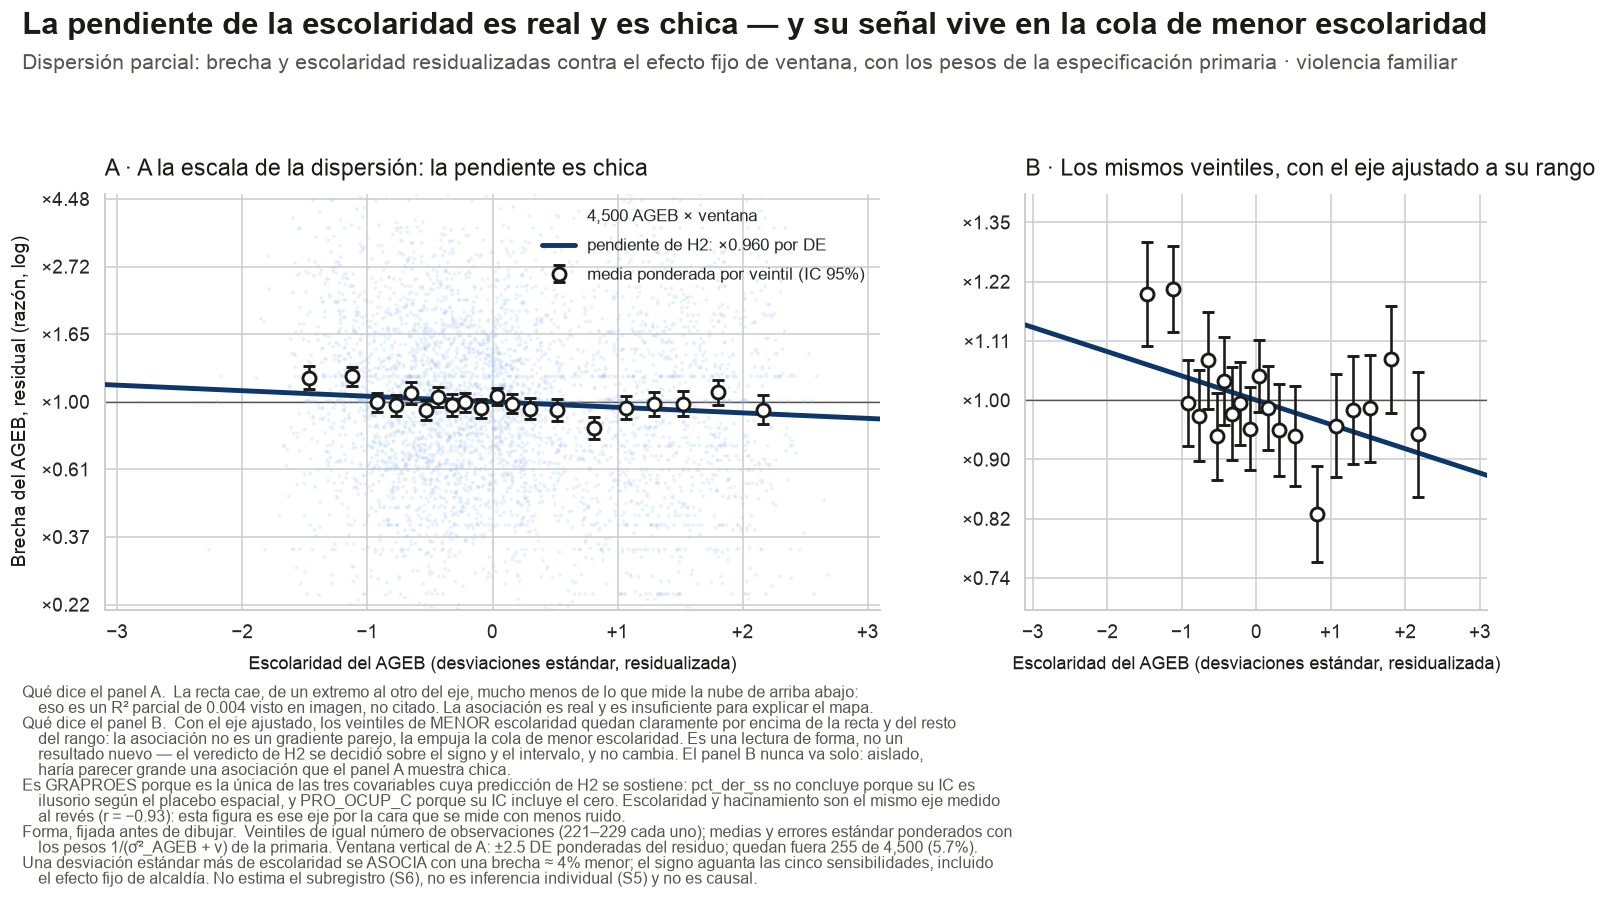

In [21]:
with mpl.rc_context(ESTILO):
    fig2 = plt.figure(figsize=(15.0, 8.4))
    ax = fig2.add_axes([.062, .320, .470, .450])          # panel A: la nube completa, ventana +-2.5 DE
    ax2 = fig2.add_axes([.620, .320, .280, .450])         # panel B: los mismos veintiles, eje ajustado a su rango
    xr = np.array([-3.1, 3.1])

    ax.axhline(0, color=TINTA2, lw=.9, zorder=1)
    ax.scatter(zt, yt, s=6, fc="#9ec5f4", ec="none", alpha=.22, zorder=2,
               label=f"{len(yt):,} AGEB × ventana")
    ax.plot(xr, b16 * xr, color="#0d366b", lw=3.2, zorder=5,
            label=f"pendiente de H2: ×{np.exp(b16):.3f} por DE")
    ax.errorbar(pt["z"], pt["y"], yerr=1.96 * pt["se"], fmt="o", ms=8.5, mfc="white", mec=TINTA,
                mew=1.9, ecolor=TINTA, elinewidth=1.7, capsize=4, zorder=6,
                label="media ponderada por veintil (IC 95%)")
    ax.set_xlim(-3.1, 3.1); ax.set_ylim(-YLIM, YLIM)
    ytk = [t for t in np.arange(-1.5, 1.51, 0.5) if abs(t) <= YLIM]
    ax.set_yticks(ytk); ax.set_yticklabels([f"×{np.exp(t):.2f}" for t in ytk], fontsize=12.5)
    ax.set_ylabel("Brecha del AGEB, residual (razón, log)", fontsize=12.5, color=TINTA, labelpad=8)
    ax.legend(loc="upper right", fontsize=11, frameon=False, labelspacing=.8, handletextpad=.7)
    ax.set_title("A · A la escala de la dispersión: la pendiente es chica", fontsize=15, color=TINTA,
                 loc="left", pad=12)

    # panel B: regla de forma declarada en 15 — eje y al rango de los veintiles +- su IC, mas 15%
    lo_b = float((pt["y"] - 1.96 * pt["se"]).min()); hi_b = float((pt["y"] + 1.96 * pt["se"]).max())
    mrg = .15 * (hi_b - lo_b)
    ax2.axhline(0, color=TINTA2, lw=.9, zorder=1)
    ax2.plot(xr, b16 * xr, color="#0d366b", lw=3.2, zorder=5)
    ax2.errorbar(pt["z"], pt["y"], yerr=1.96 * pt["se"], fmt="o", ms=8.5, mfc="white", mec=TINTA,
                 mew=1.9, ecolor=TINTA, elinewidth=1.7, capsize=4, zorder=6)
    ax2.set_xlim(-3.1, 3.1); ax2.set_ylim(lo_b - mrg, hi_b + mrg)
    ytk2 = [t for t in np.arange(-.4, .41, .1) if lo_b - mrg <= t <= hi_b + mrg]
    ax2.set_yticks(ytk2); ax2.set_yticklabels([f"×{np.exp(t):.2f}" for t in ytk2], fontsize=12.5)
    ax2.set_title("B · Los mismos veintiles, con el eje ajustado a su rango", fontsize=15, color=TINTA,
                  loc="left", pad=12)

    for a in (ax, ax2):
        a.set_xticks([-3, -2, -1, 0, 1, 2, 3])
        a.set_xticklabels(["−3", "−2", "−1", "0", "+1", "+2", "+3"], fontsize=12.5)
        a.set_xlabel("Escolaridad del AGEB (desviaciones estándar, residualizada)", fontsize=11.5,
                     color=TINTA, labelpad=9)
        for sp in ("top", "right"):
            a.spines[sp].set_visible(False)

    fig2.suptitle("La pendiente de la escolaridad es real y es chica — y su señal vive en la cola de menor escolaridad",
                  fontsize=20, fontweight="bold", x=.012, ha="left", y=.968, color=TINTA)
    fig2.text(.012, .905, "Dispersión parcial: brecha y escolaridad residualizadas contra el efecto fijo de ventana, "
              "con los pesos de la especificación primaria · violencia familiar",
              fontsize=13.5, color=TINTA2, ha="left")
    pie = ["Qué dice el panel A.  La recta cae, de un extremo al otro del eje, mucho menos de lo que mide la nube de arriba abajo:",
           "    eso es un R² parcial de 0.004 visto en imagen, no citado. La asociación es real y es insuficiente para explicar el mapa.",
           "Qué dice el panel B.  Con el eje ajustado, los veintiles de MENOR escolaridad quedan claramente por encima de la recta y del resto",
           "    del rango: la asociación no es un gradiente parejo, la empuja la cola de menor escolaridad. Es una lectura de forma, no un",
           "    resultado nuevo — el veredicto de H2 se decidió sobre el signo y el intervalo, y no cambia. El panel B nunca va solo: aislado,",
           "    haría parecer grande una asociación que el panel A muestra chica.",
           "Es GRAPROES porque es la única de las tres covariables cuya predicción de H2 se sostiene: pct_der_ss no concluye porque su IC es",
           "    ilusorio según el placebo espacial, y PRO_OCUP_C porque su IC incluye el cero. Escolaridad y hacinamiento son el mismo eje medido",
           "    al revés (r = −0.93): esta figura es ese eje por la cara que se mide con menos ruido.",
           f"Forma, fijada antes de dibujar.  Veintiles de igual número de observaciones ({pt['n'].min()}–{pt['n'].max()} cada uno); medias y errores estándar ponderados con",
           f"    los pesos 1/(σ̂²_AGEB + v) de la primaria. Ventana vertical de A: ±2.5 DE ponderadas del residuo; quedan fuera {fuera} de {len(yt):,} ({fuera/len(yt):.1%}).",
           "Una desviación estándar más de escolaridad se ASOCIA con una brecha ≈ 4% menor; el signo aguanta las cinco sensibilidades, incluido",
           "    el efecto fijo de alcaldía. No estima el subregistro (S6), no es inferencia individual (S5) y no es causal."]
    for i, t in enumerate(pie):
        fig2.text(.012, .238 - i * .0168, t, fontsize=10.2, color=TINTA2, va="top")
    fig2.savefig(FIG / "3.2_dispersion_parcial_escolaridad.png", dpi=DPI)
    plt.show()

**Interpretación (figura 2).** Los dos paneles separan dos lecturas que se estorban cuando están en el mismo eje. En el **panel A**, a la escala de la dispersión real de la brecha, la recta de H2 baja de un extremo al otro del eje **mucho menos de lo que mide la nube de arriba abajo**: eso es lo que significa un R² parcial de 0.0037, y es más convincente verlo que leerlo. En el **panel B**, con el eje ajustado al rango de los veintiles, aparece algo que la tabla no deja ver: la asociación **no es un gradiente parejo**. Los veintiles de menor escolaridad están claramente por encima de la recta y por encima del cero, y de ahí hacia la derecha los veintiles son **planos dentro de su intervalo**. La pendiente negativa es real —el signo aguanta las cinco sensibilidades y el placebo— y la empuja sobre todo la cola de menor escolaridad.

Eso **no reabre el veredicto** ni lo matiza: la regla del §3.4 se decidió sobre el signo, el intervalo primario y la estabilidad, y los tres siguen donde estaban. Es una lectura de **forma**, y es la que corresponde decir en voz alta en lugar de insinuar un gradiente lineal que la figura no muestra. Para el escrito y para el deck la frase es: *la brecha se asocia a la baja con la escolaridad del territorio, y lo que más separa es el extremo de menor escolaridad.*

*Supuesto de la residualización:* residualizo contra el efecto fijo de ventana asumiendo que la diferencia de nivel entre 2019 y 2021–22 —la brecha de la ciudad cae 1.00 → 0.82— es una diferencia de régimen de los dos canales y no parte de la asociación con la escolaridad. Si esa caída estuviera correlacionada con la escolaridad del territorio, el efecto fijo absorbería parte de la asociación y la pendiente quedaría subestimada; el contraste que existe es V1–V5, donde el signo no cambia. La pendiente dibujada es, por el teorema de Frisch–Waugh–Lovell, **exactamente** el β de `16_`, y el notebook lo verifica con un `assert` contra la cifra publicada antes de dibujar: la figura no re-estima nada.

*Supuesto del panel B, declarado como regla de forma:* el eje y del panel B se ajusta al rango de los veintiles más sus intervalos, con 15% de margen. Es un **acercamiento**, no otra escala del fenómeno, y por eso va al lado del panel A y nunca solo: visto aislado, el panel B haría parecer grande una asociación que el panel A muestra chica. La decisión de poner el acercamiento se tomó **después** de ver que a ±2.5 DE los veintiles son indistinguibles entre sí; lo que no se cambió es la regla de la ventana de A, que sigue siendo la que se fijó antes de dibujar.

### 15.3 Figura 3 — el mapa de los residuos, en la escala del mapa hero

**El punto de esta figura es lo que la covariable NO explica.** Se pinta el residuo de la primaria simple de `GRAPROES` —la misma y, los mismos pesos, el mismo efecto fijo de ventana—, promediado entre las dos ventanas por AGEB, **en la misma escala divergente en log con límites ±2σ_AGEB (×1.89 / ×0.53) del mapa hero del 2.6**. Las dos figuras están hechas para ponerse una al lado de la otra: si el mosaico de 1–2 km sigue ahí después de quitar la escolaridad, ese es el argumento visual de que **H2 acota una dirección y no explica el mapa**.

*Por qué el residuo es comparable con lo que pinta el mapa hero:* el hero pinta `m` = promedio entre ventanas de log-brecha centrada por ventana, y el residuo es la misma cantidad menos el efecto fijo de ventana (ajustado) y menos β·z(escolaridad). Es decir, **la misma escala y la misma unidad**, con un término más restado. Lo único que cambia entre las dos figuras es ese término.

*Supuesto del promedio entre ventanas:* promedio los dos residuos del AGEB asumiendo, igual que el 2.6, que lo que interesa es la parte que **se repite** —σ²_AGEB×ventana = 0.070 es del orden de σ²_AGEB = 0.102, así que una sola ventana mezclaría lo estable con lo que no se repite—. Si el mosaico fuera de una sola ventana, el promedio lo diluiría; el 2.3 ya mostró que el orden se repite (ρ = 0.30, p = 0.001).

*Tratamiento de los AGEB sin dato, igual que en el 2.6:* en **gris**, sin color y sin hachura. Son los **139** AGEB sin carpetas en una de las dos ventanas —exactamente los mismos del mapa hero— más los **44** que las exclusiones de S5 del 2.2 sacaron del universo de estimación (viviendas 0, `*` de confidencialidad, < 50 viviendas), que juntos son el 0.90% de las carpetas: **183** en total. De esos 183, **181 se dibujan en gris**; los otros 2 son los AGEB sin polígono (`0901101101107`, `0901201351227`), que quedan fuera de toda operación geométrica desde el 2.6 y por eso el mapa tiene 2,431 polígonos y no 2,433. La leyenda lo dice con los números separados, para que la comparación con el hero no engañe.

In [22]:
# --- residuos de la primaria simple de GRAPROES: se REUSA ajusta() de la seccion 8, sin redefinirla ---
_, w_r, e_r, b_r = ajusta(pan, S2["prin"], [COV_F])
assert np.isclose(b_r[0], b16, atol=1e-10) and round(float(b_r[0]), 4) == B16, "ajusta() no reproduce el beta de 16_"
_, _, e_0, _ = ajusta(pan, S2["prin"], [])                 # mismo modelo sin la covariable, para contrastar
RES_AGEB = pd.Series(e_r, index=pan["ageb"].to_numpy()).groupby(level=0).mean()
RES_0    = pd.Series(e_0, index=pan["ageb"].to_numpy()).groupby(level=0).mean()
print(f"AGEB con residuo: {len(RES_AGEB):,} | varianza del promedio por AGEB sin la covariable {RES_0.var():.4f} "
      f"-> con la covariable {RES_AGEB.var():.4f} ({1 - RES_AGEB.var()/RES_0.var():.2%} menos)")
print(f"AGEB que saturan la escala (|residuo| > 2 sigma_AGEB): {int((RES_AGEB.abs() > LIM).sum()):,} de {len(RES_AGEB):,}")

# --- geometria: el MISMO shapefile ya cargado y proyectado en la seccion 7 ---
GEO = shp.set_index("ageb")[["geometry"]].copy()
GEO["alcaldia"] = shp.set_index("ageb")["alc"].map(norm)
ALC_POLY = GEO.dissolve("alcaldia")
XL, YL = GEO.total_bounds[[0, 2]], GEO.total_bounds[[1, 3]]
sin_dato = len(GEO) - GEO.index.isin(RES_AGEB.index).sum()
n_fuera_uni = int(len(GEO) - GEO.index.isin(pd.read_csv(OUT / "11_ageb_brecha_por_delito.csv", dtype={"ageb": str})
                   .query("delito == 'violencia_familiar' and carpetas >= 1")
                   .groupby("ageb")["ventana"].nunique().pipe(lambda s: s[s == 2]).index).sum())
print(f"polígonos: {len(GEO):,} | con residuo (color): {len(GEO) - sin_dato:,} | en gris: {sin_dato} "
      f"(de los cuales {n_fuera_uni} son los del mapa hero y {sin_dato - n_fuera_uni} las exclusiones de S5)")

AGEB con residuo: 2,250 | varianza del promedio por AGEB sin la covariable 0.3439 -> con la covariable 0.3396 (1.25% menos)
AGEB que saturan la escala (|residuo| > 2 sigma_AGEB): 554 de 2,250
polígonos: 2,431 | con residuo (color): 2,250 | en gris: 181 (de los cuales 137 son los del mapa hero y 44 las exclusiones de S5)


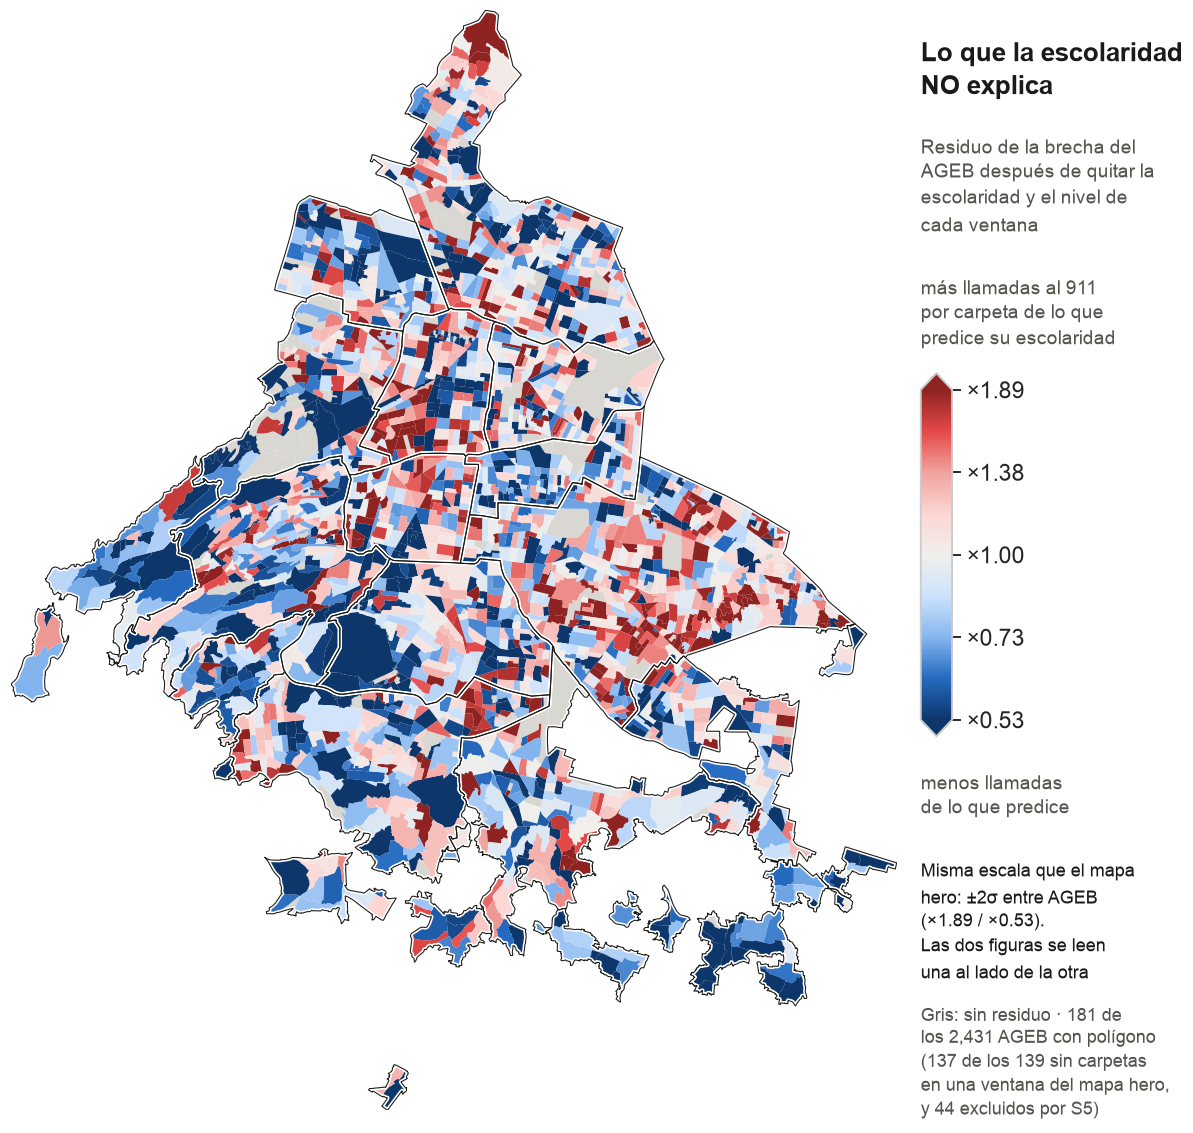

['2.5_diagnostico_ageb.png', '2.6_mapa_brecha_conteo_alto.png', '2.6_mapa_brecha_por_ventana.png', '2.6_mapa_brecha_violencia_familiar_ageb.png', '2.6_mapa_hero_violencia_familiar.png', '2.6_zoom_mosaico_1km.png', '3.2_coeficientes_h2.png', '3.2_dispersion_parcial_escolaridad.png', '3.2_mapa_residuos_h2.png']


In [23]:
AR = (XL[1] - XL[0]) / (YL[1] - YL[0])        # misma geometria de panel que el mapa hero del 2.6
H_IN, FRANJA = 10.0, 2.9
W_MAP = H_IN * AR; W_IN = W_MAP + FRANJA; FM = W_MAP / W_IN

with mpl.rc_context(ESTILO):
    fig3 = plt.figure(figsize=(W_IN, H_IN))
    axm = fig3.add_axes([0, 0, FM, 1]); axm.set_axis_off()
    v = RES_AGEB.reindex(GEO.index)
    GEO[v.isna()].plot(ax=axm, color=GRIS, ec="none")
    GEO[v.notna()].assign(_v=v[v.notna()].clip(-LIM, LIM)).plot(ax=axm, column="_v", cmap=CMAP, norm=NORM, ec="none")
    ALC_POLY.boundary.plot(ax=axm, ec="white", lw=2.8, zorder=4)
    ALC_POLY.boundary.plot(ax=axm, ec=TINTA, lw=.7, zorder=4)
    axm.set_xlim(*XL); axm.set_ylim(*YL)

    xt = FM + .020
    fig3.text(xt, .975, "Lo que la escolaridad\nNO explica", fontsize=17, color=TINTA, va="top",
              linespacing=1.35, fontweight="bold")
    fig3.text(xt, .888, "Residuo de la brecha del\nAGEB después de quitar la\nescolaridad y el nivel de\ncada ventana",
              fontsize=12.5, color=TINTA2, va="top", linespacing=1.45)
    fig3.text(xt, .760, "más llamadas al 911\npor carpeta de lo que\npredice su escolaridad",
              fontsize=12.5, color=TINTA2, va="top", linespacing=1.45)
    cax = fig3.add_axes([xt, .340, .026, .330])
    cb = fig3.colorbar(mpl.cm.ScalarMappable(norm=NORM, cmap=CMAP), cax=cax, orientation="vertical", extend="both")
    tk = [-LIM, -SD_AGEB, 0, SD_AGEB, LIM]
    cb.set_ticks(tk); cb.set_ticklabels([f"×{np.exp(x):.2f}" for x in tk]); cb.ax.tick_params(labelsize=15)
    fig3.text(xt, .310, "menos llamadas\nde lo que predice",
              fontsize=12.5, color=TINTA2, va="top", linespacing=1.45)
    fig3.text(xt, .228, f"Misma escala que el mapa\nhero: ±2σ entre AGEB\n(×{np.exp(LIM):.2f} / ×{np.exp(-LIM):.2f}).\n"
              f"Las dos figuras se leen\nuna al lado de la otra",
              fontsize=12, color=TINTA, va="top", linespacing=1.45)
    fig3.text(xt, .098, f"Gris: sin residuo · {sin_dato} de\nlos {len(GEO):,} AGEB con polígono\n"
              f"({n_fuera_uni} de los {n_fuera_uni + 2} sin carpetas\nen una ventana del mapa hero,\n"
              f"y {sin_dato - n_fuera_uni} excluidos por S5)",
              fontsize=11.5, color=TINTA2, va="top", linespacing=1.45)
    fig3.savefig(FIG / "3.2_mapa_residuos_h2.png", dpi=DPI)
    plt.show()
print(sorted(p.name for p in FIG.glob("*.png")))

**Interpretación (figura 3).** El mosaico está entero. Puesto al lado del mapa hero, el residuo **se ve igual**: AGEB en rojo y en azul intensos pegados uno al otro, dentro de la misma alcaldía, con las fronteras de alcaldía cruzando por en medio sin separar bloques de color, y **la misma proporción de AGEB saturando la escala** (554 de 2,250, el 24.6%, contra 589 de 2,294 —el 25.7%— en el hero). Quitar la escolaridad —la única covariable cuya predicción de H2 se sostiene— reduce la varianza del promedio por AGEB de 0.3439 a 0.3396, un **1.25%**. Es del mismo orden que el R² parcial de 0.0037 que `16_` reporta sobre las 4,500 observaciones ponderadas, y mide lo mismo con otra unidad: lo que la covariable se lleva del mapa es casi nada.

Esa es la afirmación que esta figura sostiene y que no se puede sostener con una tabla: **H2 acota una dirección —la brecha se asocia a la baja con la escolaridad del territorio, también entre AGEB de la misma alcaldía— y no explica el mapa.** Lo que el mapa pide, y que H2 no puede dar, es información a grano de barrio que no existe en el Censo: por eso la recomendación del §5.5 que importa es la llave que cruce folio de llamada con carpeta, no una covariable más.

*Supuesto de lectura, en el formato del criterio transversal:* leo la permanencia del mosaico como evidencia de que la covariable no explica la variación territorial, asumiendo que la escala y el universo son los mismos que en el mapa hero —lo son por construcción: misma σ_AGEB de `13_`, misma paleta, mismo promedio entre ventanas, mismo gris para quien no tiene dato—. Si la escala se hubiera reajustado a la dispersión del residuo, un mosaico idéntico se vería igual de intenso **aunque** la varianza hubiera caído, y la figura mentiría; mantener ±2σ_AGEB fijo es lo que la hace comparable. Lo que esta figura **no** dice es que no exista ninguna covariable capaz de explicar el mosaico: dice que estas tres, al grano del AGEB, no lo hacen.

## 16. 🔒 Congelamiento de cifras — 19 de octubre de 2026

Con el 3.2 **D4 queda cerrado del todo** y, con él, todo el análisis del caso. `PLAN_31_OCT.md` §3.8 fijó esta fecha: **después del 19 de octubre no se corre ningún análisis nuevo**. Del 20 al 31 solo se construye con las cifras ya calculadas —app (D5, desde el 20), escrito (D8, desde el 25) y deck (D6, desde el 28)—.

Lo que el congelamiento significa en términos operativos:

- Las **16 tablas** de `resultados/` y las **9 figuras** de `resultados/figuras/` son la fuente única de toda cifra que aparezca en la app, el escrito o el deck. Ninguna cifra se vuelve a calcular a mano ni se redondea de memoria.
- Los cuatro `build_eda*.py` se pueden regenerar y re-ejecutar, y **tienen que producir los mismos bytes**. La celda siguiente lo verifica para `12_` y `16_` y para las seis figuras anteriores al 3.2.
- Si una cifra hiciera falta y no estuviera calculada, se marca **[verificar]** y se decide si vale la pena romper el congelamiento. La respuesta por defecto, con un día de holgura en el calendario, es **no**.

In [24]:
import hashlib
ESPERADO = {
    "12_ageb_covariables_resageburb.csv":          "ec6675f367e366f7c628446cf8799c4a",
    "16_h2_regresion_brecha_covariables.csv":      "bd9df4c0f4d51d84bbf29a53270f8cd5",
    "figuras/2.5_diagnostico_ageb.png":            "150a04e23f05487179d7ea52bd3c34f4",
    "figuras/2.6_mapa_brecha_conteo_alto.png":     "09849fd218b9e9fd49740a4c253d365f",
    "figuras/2.6_mapa_brecha_por_ventana.png":     "f47681cb84caff071337285458267421",
    "figuras/2.6_mapa_brecha_violencia_familiar_ageb.png": "13c822c8321322c069070ce9cd4895d7",
    "figuras/2.6_mapa_hero_violencia_familiar.png":        "cfc7f8eddde82e890ef9225078108693",
    "figuras/2.6_zoom_mosaico_1km.png":            "2c778d6157e5458c3481c8e39b3c3d72",
}
chk = []
for rel, h in ESPERADO.items():
    f = OUT / rel
    got = hashlib.md5(f.read_bytes()).hexdigest() if f.exists() else "FALTA"
    chk.append(dict(archivo=rel, esperado=h[:12], obtenido=got[:12], identico=(got == h)))
chk = pd.DataFrame(chk)
display(chk)
if chk["identico"].all():
    print("\n🔒 CONGELAMIENTO INTACTO: las 2 tablas y las 6 figuras anteriores al 3.2 salen byte a byte idénticas.")
else:
    print("\n⚠️ EL CONGELAMIENTO SE ROMPIÓ en:", chk.loc[~chk['identico'], 'archivo'].tolist(),
          "\nHay que entender por qué ANTES de seguir con la app, el escrito o el deck.")
print("\nfiguras en resultados/figuras/:")
for p in sorted(FIG.glob("*.png")):
    print(f"  {p.name:46s} {p.stat().st_size/1024:7.0f} KB")

,archivo,esperado,obtenido,identico
0,12_ageb_covariables_resageburb.csv,ec6675f367e3,ec6675f367e3,True
1,16_h2_regresion_brecha_covariables.csv,bd9df4c0f4d5,bd9df4c0f4d5,True
2,figuras/2.5_diagnostico_ageb.png,150a04e23f05,150a04e23f05,True
3,figuras/2.6_mapa_brecha_conteo_alto.png,09849fd218b9,09849fd218b9,True
4,figuras/2.6_mapa_brecha_por_ventana.png,f47681cb84ca,f47681cb84ca,True
5,figuras/2.6_mapa_brecha_violencia_familiar_ageb.png,13c822c83213,13c822c83213,True
6,figuras/2.6_mapa_hero_violencia_familiar.png,cfc7f8eddde8,cfc7f8eddde8,True
7,figuras/2.6_zoom_mosaico_1km.png,2c778d6157e5,2c778d6157e5,True



🔒 CONGELAMIENTO INTACTO: las 2 tablas y las 6 figuras anteriores al 3.2 salen byte a byte idénticas.

figuras en resultados/figuras/:
  2.5_diagnostico_ageb.png                           486 KB
  2.6_mapa_brecha_conteo_alto.png                    704 KB
  2.6_mapa_brecha_por_ventana.png                   1226 KB
  2.6_mapa_brecha_violencia_familiar_ageb.png       1047 KB
  2.6_mapa_hero_violencia_familiar.png              1151 KB
  2.6_zoom_mosaico_1km.png                           450 KB
  3.2_coeficientes_h2.png                            322 KB
  3.2_dispersion_parcial_escolaridad.png             642 KB
  3.2_mapa_residuos_h2.png                          1206 KB


## 17. Qué deja el 3.2

- **Tres PNG** en `resultados/figuras/`, con nombres estables y a 200 dpi: `3.2_coeficientes_h2.png` (slide 14 y tercera figura del escrito), `3.2_dispersion_parcial_escolaridad.png` y `3.2_mapa_residuos_h2.png` (respaldo del deck y apoyo del §4 del escrito). **Sin CSV nuevo:** todas sus cifras ya estaban en `16_`.
- **La frase que sostienen las tres juntas**, y que es la de la slide 14: *de las tres predicciones de signo de H2, una se sostiene y dos no concluyen; ninguna se rechaza. La que se sostiene —la escolaridad— se asocia con una brecha ≈ 4% menor por desviación estándar, aguanta el efecto fijo de alcaldía y pasa el placebo espacial; y aun así no explica el mapa.*
- **Lo que no sostienen, y hay que decirlo igual:** no estiman el subregistro (S6), no son inferencia individual (S5), no son causales, y los tres renglones de la figura 1 **no son tres pruebas independientes** porque escolaridad y hacinamiento son el mismo eje medido al revés (r = −0.93).
- 🔒 **Las cifras quedan congeladas.** Lo que sigue el 20 de octubre es la **app (4.1)**: `app/build_app_data.py`, shapefile → TopoJSON simplificado y pre-proyectado por debajo de 1.5 MB, más el JSON de datos por AGEB × ventana con las dos variantes de S1, verificando que los 2,433 AGEB sobreviven la simplificación y que la clave `ageb` une al 100%.